# Influenza B NA: sampling, tree, temporal rooting, dating and substitution timeline (Colab)
Runs the whole 899-sequence pipeline end to end, **including the selection of the sequences**:
sampling (30 per year + 33 named strains) → MAFFT → IQ-TREE (FLU+G4) → temporal rooting → single clock → node dating → Fitch substitutions → timeline, A4 tree, phylogram, root-to-tip plots.

**Two ways to start (step 3):**
- **A. Full data (recommended):** upload the two GISAID files (`..._half_I.txt`, `..._half_II.txt`, headers `strain|EPI_ISL|lineage|strain|date`). Step 3A rebuilds the 899-sequence set with the same rule and seed as the original analysis.
- **B. Already sampled:** upload `sequences.fasta` (headers `name__EPI_ISL_xxx__L__YYYY-MM-DD`, L = V, Y or U) + `required.tsv`; or `aln_c2.fa` + `nc.treefile` + `required.tsv` to skip alignment and tree.

**Sampling rule (step 3A):** one record per EPI_ISL id; candidates are HA-Victoria or HA-Yamagata, 460–470 residues, ≤2 X, no stop codon, parsable year. The 33 named strains are always included. Each year's quota is 30 minus its named strains; candidates of each lineage are shuffled (seed 3), duplicate sequences within the year and lineage are dropped, and Victoria/Yamagata are alternated until the quota is full or candidates run out.

Expected on the original data: pooled rate 0.00331, root 1982.3, R² 0.927 (897/899 tips); split ~1995.3; Victoria clade root ~1999.0.

## 1. Install MAFFT and IQ-TREE

In [1]:
import os, subprocess, glob
!apt-get -qq install -y mafft > /dev/null
if not os.path.exists('/content/iqtree2'):
    !wget -q https://github.com/iqtree/iqtree2/releases/download/v2.4.0/iqtree-2.4.0-Linux-intel.tar.gz -O /content/iq.tgz
    !tar -xzf /content/iq.tgz -C /content
    cand = glob.glob('/content/iqtree-*/bin/iqtree*')
    !cp {cand[0]} /content/iqtree2 && chmod +x /content/iqtree2
!mafft --version
!/content/iqtree2 --version | head -1

v7.505 (2022/Apr/10)
IQ-TREE multicore version 2.4.0 for Linux x86 64-bit built Feb  7 2025


## 2. Write the analysis code

In [21]:
import os
os.makedirs('/content/ibv_code', exist_ok=True)

with open('/content/ibv_code/common.py', 'w') as f:
    f.write('''# Shared code: parsing, alignment, tree, temporal rooting, Fitch parsimony, numbering. Not run directly.
import sys,re,collections,math,os
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

TREE=sys.argv[1]; ALN=sys.argv[3]; OUT=sys.argv[2]
REQ={}
for l in open(sys.argv[4] if len(sys.argv)>4 else 'required.tsv'):
    a,b=l.rstrip('\n').split('\t'); REQ[a]=b

# ---------- alignment ----------
seqs={};n=None
for l in open(ALN):
    l=l.strip()
    if l[0]=='>': n=re.sub(r'[^A-Za-z0-9_.\\]','_',l[1:]); seqs[n]=''
    else: seqs[n]+=l
L=len(next(iter(seqs.values())))
def meta(name):
    p=name.split('__'); return p[-2],int(p[-1][:4])   # lineage letter, year
# ---------- newick ----------
class Node:
    __slots__=('name','children','parent','length','id','tips','label')
    def __init__(s): s.name=None;s.children=[];s.parent=None;s.length=0.0;s.tips=None;s.label=None
def parse_newick(t):
    t=t.strip().rstrip(';'); pos=0
    def rd():
        nonlocal pos
        nd=Node()
        if t[pos]=='(':
            pos+=1
            while True:
                c=rd(); c.parent=nd; nd.children.append(c)
                if t[pos]==',': pos+=1; continue
                if t[pos]==')': pos+=1; break
        m=re.match(r'[^:,();]*',t[pos:]); lab=m.group(0); pos+=len(lab)
        if nd.children: nd.label=lab or None
        else: nd.name=lab
        if pos<len(t) and t[pos]==':':
            m=re.match(r":([0-9eE.+-]+)",t[pos:]); nd.length=float(m.group(1)); pos+=len(m.group(0))
        return nd
    return rd()
root=parse_newick(open(TREE).read())
def traverse(nd):
    yield nd
    for c in nd.children: yield from traverse(c)
# ---------- root on Victoria/Yamagata split ----------
def lin(nd): return meta(nd.name)[0]
def reroot_on_edge(root,child,frac=0.5):
    # rebuild rooted tree with new root on edge (child,parent)
    adj=collections.defaultdict(list)
    for nd in traverse(root):
        if nd.parent is not None:
            adj[id(nd)].append((nd.parent,nd.length)); adj[id(nd.parent)].append((nd,nd.length))
    cp=child.parent; el=child.length
    newroot=Node()
    def build(nd,frm,length):
        out=Node(); out.name=nd.name; out.label=nd.label; out.length=length
        for (o,l) in adj[id(nd)]:
            if o is frm: continue
            if (nd is child and o is cp) or (nd is cp and o is child): continue
            c=build(o,nd,l); c.parent=out; out.children.append(c)
        return out
    a=build(child,None,el*frac); b=build(cp,None,el*(1-frac))
    a.parent=newroot;b.parent=newroot;newroot.children=[a,b]
    return newroot
def leaves(nd):
    return [x for x in traverse(nd) if not x.children]
# ---------- TEMPORAL ROOTING: root-to-tip regression against sampling date (single global clock) ----------
import datetime
def tdate_(name):
    ds=name.split('__')[-1][:10]; y,m,d=map(int,ds.split('-'))
    return y+0.5 if (m,d)==(1,1) else y+(datetime.date(y,m,d)-datetime.date(y,1,1)).days/365.25

print('original root children:',len(root.children))
# ---------- fast temporal rooting: root-to-tip R2 for every edge and 101 positions along it, O(N) ----------
def _iter_post(r):
    st=[r];o=[]
    while st:
        x=st.pop(); o.append(x); st.extend(x.children)
    return o[::-1]
_po=_iter_post(root)
_tipl=[x for x in _po if not x.children]; _td={id(t):tdate_(t.name) for t in _tipl}
_tm=np.mean(list(_td.values()))
_WEIGHT=os.environ.get('VAL_WEIGHT','0')=='1'
_yc=collections.Counter(int(v_) for v_ in _td.values())
def _wt(x): return min(1.0,30.0/_yc[int(_td[id(x)])]) if _WEIGHT else 1.0
def _shift(S,l):
    n,Sd,Sdd,Sdt,St,Stt=S
    return np.array([n,Sd+n*l,Sdd+2*l*Sd+n*l*l,Sdt+l*St,St,Stt]) if np.ndim(l)==0 else np.stack([n+0*l,Sd+n*l,Sdd+2*l*Sd+n*l*l,Sdt+l*St,St+0*l,Stt+0*l])
_sub={}
for x in _po:
    if not x.children:
        t=_td[id(x)]-_tm; w=_wt(x); _sub[id(x)]=np.array([w,0,0,0,w*t,w*t*t],float)
    else:
        S=np.zeros(6)
        for c in x.children: S+=_shift(_sub[id(c)],c.length)
        _sub[id(x)]=S
_U={}; _A={id(root):_sub[id(root)]}
for x in reversed(_po):
    if x is not root: _A[id(x)]=_sub[id(x)]+_shift(_U[id(x)],x.length)
    for c in x.children: _U[id(c)]=_A[id(x)]-_shift(_sub[id(c)],c.length)
_fs=np.linspace(0,1,101); _best=(-1,None,None)
for x in _po:
    if x is root: continue
    ins=_shift(_sub[id(x)],_fs*x.length); out=_shift(_U[id(x)],(1-_fs)*x.length); S=ins+out
    n,Sd,Sdd,Sdt,St,Stt=S
    cov=Sdt-Sd*St/n; vd=Sdd-Sd*Sd/n; vt=Stt-St*St/n
    with np.errstate(all='ignore'): r2=np.where((cov>0)&(vd>0),cov*cov/(vd*vt),-1)
    k=int(np.argmax(r2))
    if r2[k]>_best[0]: _best=(float(r2[k]),x,float(_fs[k]))
print('temporal root: R2=%.3f fraction %.2f along the edge above %s'%(_best[0],_best[2],_best[1].name or '(internal, %d tips)'%len(leaves(_best[1]))))
root=reroot_on_edge(root,_best[1],_best[2])

# collapse zero-length internal branches into polytomies (changes cannot be placed on branches with no substitutions)
def collapse(nd):
    for c in list(nd.children): collapse(c)
    newc=[]
    for c in nd.children:
        if c.children and c.length<1e-4:
            for g in c.children: g.parent=nd; newc.append(g)
        else: newc.append(c)
    nd.children=newc
collapse(root)
# collapse single-child root artifacts
for i,nd in enumerate(x for x in traverse(root)): nd.id=i
for nd in traverse(root):
    nd.tips=[nd] if not nd.children else [t for c in nd.children for t in c.tips] if all(c.tips for c in nd.children) else None
def settips(nd):
    if not nd.children: nd.tips=[nd]; return nd.tips
    nd.tips=[t for c in nd.children for t in settips(c)]; return nd.tips
settips(root)
ntips=len(root.tips); print('tips',ntips)
# ---------- Fitch parsimony ancestral reconstruction (per site) ----------
AA='ACDEFGHIKLMNPQRSTVWY'
aidx={a:i for i,a in enumerate(AA)}
nodes=list(traverse(root))
tipmask={}
M=np.zeros((len(nodes),L),dtype=np.uint32)   # bitset of allowed states
for nd in nodes:
    if not nd.children:
        s=seqs[nd.name]
        arr=np.array([ (1<<aidx[c]) if c in aidx else (1<<20)-1 if c!='-' else (1<<21)-1 for c in s],dtype=np.uint32)
        M[nd.id]=arr
order=list(traverse(root))[::-1]
# post-order
def post(nd):
    for c in nd.children: post(c)
    if nd.children:
        cm=[M[c.id] for c in nd.children]
        if len(cm)==2:
            inter=cm[0]&cm[1]
            M[nd.id]=np.where(inter!=0,inter,cm[0]|cm[1])
        else:
            # multifurcation (zero-length branches): order-independent rule - keep the states present in the
            # largest number of child sets (pairwise Fitch folding is order dependent and can invent spurious changes)
            cnt=np.zeros((20,len(cm[0])),dtype=np.int32)
            for x in cm:
                for st in range(20): cnt[st]+=((x>>st)&1).astype(np.int32)
            mx=cnt.max(axis=0)
            out=np.zeros(len(cm[0]),dtype=np.uint32)
            for st in range(20): out|=np.where(cnt[st]==mx,np.uint32(1<<st),np.uint32(0))
            M[nd.id]=out
sys.setrecursionlimit(10**6)
post(root)
ST=np.zeros((len(nodes),L),dtype=np.int16)
def pick(mask,pref):
    out=np.empty(len(mask),dtype=np.int16)
    for i,m in enumerate(mask):
        if pref[i]>=0 and (int(m)>>int(pref[i]))&1: out[i]=pref[i]
        else: out[i]=(int(m)&-int(m)).bit_length()-1
    return out
_pref=np.full(L,-1)
if False:
    # polarise with the ancestral (root) state reconstructed in the original 899-sequence analysis (matched by reference position number)
    _rs=dict(l.split() for l in open('orig_root_states.tsv'))
    for _i in range(L):
        _p=colnum.get(_i) if 'colnum' in globals() else None
    _cn={}; _k=0
    _recent=[seqs[t.name] for t in root.tips if meta(t.name)[0]=='V' and meta(t.name)[1]>=2023]
    _cons=''.join(collections.Counter(s_[i] for s_ in _recent).most_common(1)[0][0] for i in range(L))
    for _i,_ch in enumerate(_cons):
        if _ch!='-': _k+=1; _cn[_i]=_k
    for _i,_p in _cn.items():
        _r=_rs.get(str(_p))
        if _r in aidx: _pref[_i]=aidx[_r]
elif os.environ.get('VAL_POLAR','0')=='1':
    # polarise the root state with the oldest sampled viruses (earliest 10 tips): where the Fitch root set contains their majority residue, use it
    _old=sorted(root.tips,key=lambda t:tdate_(t.name))[:10]
    for _i in range(L):
        _c=collections.Counter(seqs[t.name][_i] for t in _old if seqs[t.name][_i] in aidx)
        if _c: _pref[_i]=aidx[_c.most_common(1)[0][0]]
ST[root.id]=pick(M[root.id],_pref)
def pre(nd):
    for c in nd.children:
        if c.children: ST[c.id]=pick(M[c.id],ST[nd.id])
        else: ST[c.id]=np.array([ (aidx.get(ch,-1)) for ch in seqs[c.name]],dtype=np.int16)
        pre(c)
pre(root)
# reference numbering: use consensus of Victoria 2023-2025 tips, skipping columns that are gap in it
recent=[seqs[t.name] for t in root.tips if meta(t.name)[0]=='V' and meta(t.name)[1]>=2023]
cons=''.join(collections.Counter(s[i] for s in recent).most_common(1)[0][0] for i in range(L))
colnum={};k=0
for i,ch in enumerate(cons):
    if ch!='-': k+=1; colnum[i]=k
def changes(nd):
    """aa changes on branch leading to nd (parent -> nd)"""
    if nd.parent is None: return []
    out=[]
    a=ST[nd.parent.id]; b=ST[nd.id]
    for i in np.nonzero(a!=b)[0]:
        if a[i]<0 or b[i]<0: continue
        if i not in colnum: continue
        out.append((colnum[i],AA[a[i]],AA[b[i]]))
    return out
for nd in nodes: nd.label=None
import pickle
pickle.dump({'nodes':nodes},open(OUT+'_nodes.pkl','wb')) if False else None

def xpos_pre(nd):
    d=0
    while nd.parent is not None: d+=nd.length; nd=nd.parent
    return d
byid={nd.id:nd for nd in nodes}
def lineage_of(nd):
    c=collections.Counter(t.label or meta(t.name)[0] for t in nd.tips if (t.label or meta(t.name)[0])!='U'); return c.most_common(1)[0][0] if c else 'V'
epi=lambda nm: nm.split('__')[-3]
''')
print('File successfully written to /content/ibv_code/common.py')

written: ['00_sample_899.py', '02_dating.py', '03_timeline_figure.py', '04_tree_A4_figure.py', '05a_root_to_tip_pooled.py', '05b_root_to_tip_by_lineage.py', '06_phylogram_A4_figure.py', '__pycache__', 'boot.py', 'common.py']


In [26]:
import glob
for f in sorted(glob.glob('/content/ibv_code/*.py')):
    print('='*30, f); print(open(f).read())

============================== /content/ibv_code/00_sample_899.py
# Build the 899-sequence analysis set from the full GISAID NA files.
# usage: python3 sample_899.py half_I.txt half_II.txt   (files in this order)
# writes sequences.fasta (name__EPI_ISL_xxx__L__YYYY-MM-DD) and required3.tsv
import sys,re,random,collections
files=[f for f in sys.argv[1:] if 'half' in f]   # only the GISAID half files (other uploads are ignored)
WANT="""B/NORWAY/2134/2019 B/NAGASAKI/474/2018 B/NEWYORK/15/2020 B/PHUKET/3073/2013 B/WAKAYAMA/152/2013 B/ATTECOUBE/GR1101/2011 B/WISCONSIN/01/2010 B/JORDAN/358/2006 B/INDIA/C117528/2010 B/OKLAHOMA/WRAIR1587P/2009 B/HOUSTON/B56/1997 B/NEWYORK/1005/1995 B/NEWYORK/347/1999 B/SHANGHAISONGJIANG/176/2011 B/BEIJINGHUAIROU/14042/2014 B/MALAYSIA/2506/2004 B/COLORADO/03/2011 B/VICTORIA/303/2006 B/NEWYORK/1084/2005 B/FIJI/11/2011 B/ENGLAND/243/2011 B/LAOS/I117/2012 B/BRISBANE/60/2008 B/YASOTHON/381/2019 B/BANGLADESH/1746/2019 B/WASHINGTON/02/2019 B/LEBANON/16/2020 B/COLORAD

In [5]:
%%writefile /content/ibv_code/boot.py
import sys,os,threading
HERE=os.path.dirname(os.path.abspath(__file__))
os.chdir(os.environ.get('IBV_DIR','.')); sys.setrecursionlimit(10**6); threading.stack_size(1<<29)
def load_common(prefix='t3'):
    sys.argv=['x','nc.treefile',prefix,'aln_c2.fa','required3.tsv']
    g={'__name__':'vh'}; exec(open(os.path.join(HERE,'common.py')).read(),g); return g

Writing /content/ibv_code/boot.py


In [6]:
%%writefile /content/ibv_code/02_dating.py
"""Validation run: dating (single global clock, as in the original), lineage-specific root-to-tip, substitution paths. All sequences."""
import sys,os,re,collections,datetime,json,csv,threading,pickle
HERE=os.path.dirname(os.path.abspath(__file__)); os.chdir(os.environ.get('IBV_DIR','.')); sys.setrecursionlimit(10**6); threading.stack_size(1<<29)
TREE=sys.argv[1] if len(sys.argv)>1 else 'nc.treefile'
def main():
    sys.argv=['x',TREE,os.environ.get('VAL_PREFIX','t3'),os.environ.get('VAL_ALN','aln_c2.fa'),os.environ.get('VAL_REQ','required3.tsv')]
    g={'__name__':'vh'}; exec(open(os.path.join(HERE,'common.py')).read(),g); globals().update(g)
    import numpy as np
    OUT=os.environ.get('VAL_PREFIX','t3'); byid={nd.id:nd for nd in nodes}; tips=root.tips
    Dn={root.id:0.0}
    for n in nodes:
        if n.parent is not None: Dn[n.id]=Dn[n.parent.id]+n.length
    D=lambda n:Dn[n.id]
    DT={t.id:tdate_(t.name) for t in tips}
    # Victoria NA clade: node whose tip set best matches HA-Victoria (max F1 over labelled tips)
    labV={t.id for t in tips if meta(t.name)[0]=='V'}; labY={t.id for t in tips if meta(t.name)[0]=='Y'}
    best=(0,None)
    for n in nodes:
        if not n.children or len(n.tips)<50: continue
        ids={t.id for t in n.tips}; tp=len(ids&labV); fp=len(ids&labY); fn=len(labV)-tp
        f1=2*tp/(2*tp+fp+fn)
        if f1>best[0]: best=(f1,n)
    VC=best[1]; inV={t.id for t in VC.tips}
    print('Victoria NA clade: %d tips, F1 vs HA label %.4f; HA-Y tips inside %d; HA-V tips outside %d'%(len(VC.tips),best[0],len(inV&labY),len(labV-inV)))
    x=np.array([DT[t.id] for t in tips]); y=np.array([D(t) for t in tips]); v=np.array([t.id in inV for t in tips])
    WT=os.environ.get('VAL_WEIGHT','0')=='1'
    yc=collections.Counter(int(a) for a in x); w=np.array([min(1.0,30.0/yc[int(a)]) if WT else 1.0 for a in x])
    print('weighting: %s'%('year-balanced (each calendar year counts at most 30 tips)' if WT else 'none'))
    def fit(x,y,ww=None):
        if ww is None: ww=np.ones(len(x))
        sl,ic=np.polyfit(x,y,1,w=np.sqrt(ww)); return sl,-ic/sl
    def wr2(xx,yy,ww):
        mx=(ww*xx).sum()/ww.sum(); my=(ww*yy).sum()/ww.sum()
        return ((ww*(xx-mx)*(yy-my)).sum())**2/(((ww*(xx-mx)**2).sum())*((ww*(yy-my)**2).sum()))
    def clean(m):
        idx=np.where(m)[0]; sl,t0=fit(x[idx],y[idx],w[idx]); res=y[idx]-(sl*x[idx]-sl*t0); sd=np.sqrt((w[idx]*res**2).sum()/w[idx].sum()); k=np.abs(res)<3.5*sd; return idx[k]
    kidx=clean(np.ones(len(x),bool)); keep=np.zeros(len(x),bool); keep[kidx]=True
    sl,t0=fit(x[keep],y[keep],w[keep]); r2=wr2(x[keep],y[keep],w[keep])
    rng=np.random.default_rng(1); bs=[]
    for _ in range(500):
        b=rng.choice(kidx,len(kidx)); bs.append(fit(x[b],y[b],w[b]))
    bs=np.array(bs)
    print('global clock: rate %.5f (%.5f-%.5f), root %.1f (%.1f-%.1f), R2 %.3f, %d/%d tips'%(sl,*np.percentile(bs[:,0],[2.5,97.5]),t0,*np.percentile(bs[:,1],[2.5,97.5]),r2,keep.sum(),len(tips)))
    clock=dict(rate=sl,rate_ci=list(np.percentile(bs[:,0],[2.5,97.5])),root_date=t0,root_ci=list(np.percentile(bs[:,1],[2.5,97.5])),R2=r2,tips_used=int(keep.sum()),tips_total=len(tips))
    # lineage-specific fits (free intercept) and shared-root fit
    lin_fit={}
    for lab,m in (('Victoria',v),('Yamagata',~v)):
        ii=clean(m); s_,t_=fit(x[ii],y[ii],w[ii]); r_=wr2(x[ii],y[ii],w[ii])
        B=np.array([fit(x[b],y[b],w[b]) for b in (rng.choice(ii,len(ii)) for _ in range(300))])
        lin_fit[lab]=dict(n=int(len(ii)),n_total=int(m.sum()),rate=s_,rate_ci=list(np.percentile(B[:,0],[2.5,97.5])),root=t_,root_ci=list(np.percentile(B[:,1],[2.5,97.5])),R2=r_,alpha=-s_*t_)
        print(lab,lin_fit[lab])
    ki=np.zeros(len(x),bool); ki[clean(v)]=True; ki[clean(~v)]=True
    def common(xk,yk,vk,wk):
        bst=None
        for t_ in np.arange(1940,1995,0.1):
            u=xk-t_; sv=(wk[vk]*u[vk]*yk[vk]).sum()/(wk[vk]*u[vk]**2).sum(); sy=(wk[~vk]*u[~vk]*yk[~vk]).sum()/(wk[~vk]*u[~vk]**2).sum()
            sse=(wk*(yk-np.where(vk,sv*u,sy*u))**2).sum()
            if bst is None or sse<bst[0]: bst=(sse,t_,sv,sy)
        return bst
    cb=common(x[ki],y[ki],v[ki],w[ki]); sst=(w[ki]*(y[ki]-np.average(y[ki],weights=w[ki]))**2).sum()
    CB=[]; ii=np.where(ki)[0]
    for _ in range(200):
        b=rng.choice(ii,len(ii)); CB.append(common(x[b],y[b],v[b],w[b])[1:])
    CB=np.array(CB)
    lin_fit['common_root']=dict(root=cb[1],root_ci=list(np.percentile(CB[:,0],[2.5,97.5])),rate_V=cb[2],rate_V_ci=list(np.percentile(CB[:,1],[2.5,97.5])),rate_Y=cb[3],rate_Y_ci=list(np.percentile(CB[:,2],[2.5,97.5])),pseudoR2=1-cb[0]/sst,n=int(ki.sum()))
    print('common root',lin_fit['common_root'])
    clock['lineage_fits']=lin_fit
    json.dump(clock,open(OUT+'_clock.json','w'),indent=1)
    np.savez('rtt.npz',x=x,y=y,v=v,w=w,keep=keep,ki=ki,names=np.array([t.name for t in tips]))
    # node ages
    a_t={t.id:DT[t.id]-D(t)/sl for t in tips}
    age={}
    for n in nodes:
        age[n.id]=float(np.median([a_t[t.id] for t in n.tips])+D(n)/sl) if n.children else DT[n.id]
    for n in nodes:
        if n.parent is not None and n.children: age[n.id]=max(age[n.id],age[n.parent.id])
    keepids={t.id for t,k in zip(tips,keep) if k}
    print('clock outliers:',[(t.name.split('__')[0],round(DT[t.id],1)) for t in tips if t.id not in keepids])
    for n in reversed(nodes):
        if n.children:
            cs=[age[c.id] for c in n.children if c.children or c.id in keepids]
            if cs: age[n.id]=min(age[n.id],min(cs))
    age[root.id]=min(age[root.id],t0); print('root node age %.1f'%age[root.id])
    with open(OUT+'_node_ages.tsv','w') as f:
        f.write('node_id\ttip_name\tn_tips\testimated_year\tin_NA_Victoria_clade\n')
        for n in nodes: f.write('%d\t%s\t%d\t%.2f\t%s\n'%(n.id,n.name or '',len(n.tips),age[n.id],'yes' if all(t.id in inV for t in n.tips) else 'no'))
    def nwk(n):
        s=('('+','.join(nwk(c) for c in n.children)+')') if n.children else n.name
        return s+(':%.3f'%max(age[n.id]-age[n.parent.id],0) if n.parent is not None else '')
    open(OUT+'_dated_tree.nwk','w').write(nwk(root)+';\n')
    def mrca(ts):
        paths=[]
        for t in ts:
            p=[];z=t
            while z is not None: p.append(z.id); z=z.parent
            paths.append(p[::-1])
        k=0
        while all(len(p)>k for p in paths) and len({p[k] for p in paths})==1: k+=1
        return byid[paths[0][k-1]]
    def recent_tips(ts):
        yc=collections.Counter(int(DT[t.id]) for t in ts); ymax=max(yy for yy,c in yc.items() if c>=3)
        return [t for t in ts if DT[t.id]>=ymax-1],ymax
    Vt=[t for t in tips if t.id in inV]; Yt=[t for t in tips if t.id not in inV]
    # Yamagata-type crown clade = node (not overlapping the Victoria clade) with best F1 against the HA-Yamagata label; recent Yamagata tips are taken from it
    bestY=(0,None)
    for n in nodes:
        if not n.children or len(n.tips)<50: continue
        ids={t.id for t in n.tips}
        if ids&inV: continue
        tp=len(ids&labY); fp=len(ids&labV); fn=len(labY)-tp; f1=2*tp/(2*tp+fp+fn)
        if f1>bestY[0]: bestY=(f1,n)
    YC=bestY[1]; print('Yamagata-type crown clade: %d tips, F1 vs HA label %.4f'%(len(YC.tips),bestY[0]))
    recV,yV=recent_tips(Vt); recY,yY=recent_tips([t for t in YC.tips])
    topV=mrca(recV); topY=mrca(recY)
    RB=float(os.environ.get('VAL_ROBUST','0'))
    if RB>0:
        def robust(top,rec):
            ids={t.id for t in rec}; n=top; tot=len(ids)
            while True:
                best=None;bc=0
                for c in n.children:
                    k=sum(1 for t in c.tips if t.id in ids)
                    if k>bc: best,bc=c,k
                if best is None or bc<RB*tot: return n
                n=best
        t0_V,t0_Y=topV,topY; topV=robust(topV,recV); topY=robust(topY,recY)
        print('robust MRCA (>= %.0f%% of recent tips): Victoria node %d -> %d (%d tips), Yamagata node %d -> %d (%d tips)'%(100*RB,t0_V.id,topV.id,len(topV.tips),t0_Y.id,topY.id,len(topY.tips)))
    def path_to(n):
        p=[];z=n
        while z is not None: p.append(z); z=z.parent
        return p[::-1]
    pV=path_to(topV); pY=path_to(topY)
    k=0
    while k<min(len(pV),len(pY)) and pV[k] is pY[k]: k+=1
    div=pV[k-1]; shared=pV[:k]; onlyV=pV[k:]; onlyY=pY[k:]
    print('divergence node age %.1f; shared trunk %d, V-only %d, Y-only %d; recent V (>=%d) %d tips, recent Y (>=%d) %d tips'%(age[div.id],len(shared)-1,len(onlyV),len(onlyY),yV-1,len(recV),yY-1,len(recY)))
    print('Victoria clade root age %.1f'%age[VC.id])
    inv={p:i for i,p in colnum.items()}; rows=[]
    def addrows(seg,nodes_,recent):
        for nd in nodes_:
            if nd.parent is None: continue
            for pos,a_,b_ in changes(nd):
                col=inv[pos]; fr=np.mean([1 if seqs[t.name][col]==b_ else 0 for t in recent])
                rows.append(dict(segment=seg,substitution='%s%d%s'%(a_,pos,b_),position=pos,branch_node=nd.id,t_start=round(age[nd.parent.id],1),t_end=round(age[nd.id],1),t_mid=round((age[nd.parent.id]+age[nd.id])/2,1),n_descendant_tips=len(nd.tips),frac_of_recent_tips_with_derived_aa=round(float(fr),2)))
    addrows('shared trunk',shared,recY+recV); addrows('NA-Victoria lineage',onlyV,recV); addrows('NA-Yamagata lineage',onlyY,recY)
    with open(OUT+'_trunk_substitution_dates.tsv','w') as f:
        w=csv.DictWriter(f,fieldnames=list(rows[0]),delimiter='\t'); w.writeheader(); [w.writerow(r) for r in rows]
    print({s:sum(1 for r in rows if r['segment']==s) for s in ('shared trunk','NA-Victoria lineage','NA-Yamagata lineage')})
    # newick with branch lengths in subs/site of the rooted, collapsed tree (for reuse)
    def nwk2(n):
        s=('('+','.join(nwk2(c) for c in n.children)+')') if n.children else n.name
        return s+(':%.6f'%n.length if n.parent is not None else '')
    open(OUT+'_rooted_tree.nwk','w').write(nwk2(root)+';\n')
    pickle.dump(dict(age=age,clock=clock,div=div.id,VC=VC.id,topV=topV.id,topY=topY.id,shared=[n.id for n in shared],onlyV=[n.id for n in onlyV],onlyY=[n.id for n in onlyY],rows=rows,recV=[t.id for t in recV],recY=[t.id for t in recY],yV=yV,yY=yY),open(OUT+'.pkl','wb'))
    print('done',OUT)
t=threading.Thread(target=main); t.start(); t.join()

Writing /content/ibv_code/02_dating.py


In [7]:
%%writefile /content/ibv_code/03_timeline_figure.py
import sys as _s, os as _o; _s.path.insert(0,_o.path.dirname(_o.path.abspath(__file__)))
import sys,os,collections,pickle,csv
import numpy as np
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from boot import *
_g=load_common(); globals().update(_g)
P=pickle.load(open('t3.pkl','rb')); age=P['age']; clock=P['clock']; rows=P['rows']
byid={n.id:n for n in nodes}; DT={t.id:tdate_(t.name) for t in root.tips}
VC=byid[P['VC']]; div=byid[P['div']]; topV=byid[P['topV']]; topY=byid[P['topY']]
CV,CY='#8968cd','#43cd80'; CS='#555555'; C95,C80='#d62a1e','#e08a00'
inv={p:i for i,p in colnum.items()}
inVs={t.id for t in VC.tips}
grp={'NA-Victoria':[t for t in root.tips if t.id in inVs],'NA-Yamagata':[t for t in root.tips if t.id not in inVs]}
recent={'NA-Victoria':[byid[i] for i in P['recV']],'NA-Yamagata':[byid[i] for i in P['recY']]}
def freqs(col,lg):
    c=collections.Counter(seqs[t.name][col] for t in recent[lg]); c.pop('-',None); c.pop('X',None); n=sum(c.values()); return c,n
# lineage-defining in AT LEAST ONE lineage, measured on the RECENT viruses of that lineage (V >=2024, Y >=2019): derived residue in >95% (major) or >80%,
# and it is not the majority residue of the other lineage's recent viruses (so it discriminates the lineages); reversed changes drop out automatically
sel=[];info={}
for r in rows:
    lg={'NA-Victoria lineage':'NA-Victoria','NA-Yamagata lineage':'NA-Yamagata'}.get(r['segment'])
    if not lg: continue
    col=inv[r['position']]; der=r['substitution'][-1]; oth='NA-Yamagata' if lg=='NA-Victoria' else 'NA-Victoria'
    c,n=freqs(col,lg); fo=c[der]/n; c2,n2=freqs(col,oth); om=c2.most_common(1)[0][0]
    if fo<=0.80 or om==der: continue
    info[id(r)]=(fo,'major' if fo>0.95 else 'lineage'); sel.append((lg,r))
print([(lg,r['substitution'],r['t_mid'],round(info[id(r)][0],3),info[id(r)][1]) for lg,r in sel])
def D_(nd):
    d=0
    while nd.parent is not None: d+=nd.length; nd=nd.parent
    return d
def rng90(n):
    v=np.array([DT[t.id]-(D_(t)-D_(n))/clock['rate'] for t in n.tips if not t.name.startswith('B_Andalucia')]); return np.percentile(v,[5,95])
bd=rng90(div); bv=rng90(VC); t_root=age[root.id]; t_div=age[div.id]; vr=age[VC.id]
tmV=float(np.median([DT[i] for i in P['recV']])); tmY=float(np.median([DT[i] for i in P['recY']]))
import math
nStr_V=23; nStr_Y=11
YV=2.0; YY=YV-(0.5+0.23*nStr_V+0.5+0.23*nStr_Y+0.8); YT=(YV+YY)/2
nV=sum(1 for lg,r in sel if lg=='NA-Victoria'); nY=sum(1 for lg,r in sel if lg=='NA-Yamagata')
topY_=YV+0.35+0.27*nV+0.25; botY_=YY-(0.35+0.27*nY)-0.35
fig,ax=plt.subplots(figsize=(13.5,0.5*(topY_-botY_)+0.9))
ax.axvspan(bd[0],bd[1],ymin=0.04,ymax=0.96,color='#999',alpha=0.13,lw=0,zorder=0)
ax.add_patch(plt.Rectangle((bv[0],YV-0.16),bv[1]-bv[0],0.32,color=CV,alpha=0.22,lw=0,zorder=0))
ax.plot([t_root,t_div],[YT,YT],color=CS,lw=3.5,solid_capstyle='butt'); ax.plot([t_div,t_div],[YY,YV],color=CS,lw=3.5)
ax.plot([t_div,age[topV.id]],[YV]*2,color=CV,lw=3.5); ax.plot([age[topV.id],tmV],[YV]*2,color=CV,lw=3,ls=(0,(1.4,1.4)))
ax.plot([t_div,age[topY.id]],[YY]*2,color=CY,lw=3.5); ax.plot([age[topY.id],tmY],[YY]*2,color=CY,lw=3,ls=(0,(1.4,1.4)))
ax.plot(t_root,YT,'s',color='k',ms=8); ax.text(t_root-0.5,YT,'root\n~%.0f'%t_root,ha='right',va='center',fontsize=9,fontweight='bold')
ax.plot(t_div,YT,'o',color='k',ms=7)
ax.text(t_div-0.5,YT-0.28,'split ~%.0f\n(90%%: %.0f–%.0f)'%(t_div,bd[0],bd[1]),ha='right',va='top',fontsize=8.5,fontweight='bold')
ax.plot(vr,YV,'s',color=CV,ms=6,zorder=5); ax.text(bv[0],YV-0.27,'Victoria clade root ~%.0f\n(90%%: %.0f–%.0f)'%(vr,bv[0],bv[1]),ha='left',va='top',fontsize=7,color=CV,linespacing=1.0)
ax.text(tmV+0.4,YV,'NA-Victoria\n(to ~%.0f)'%tmV,fontsize=9.5,fontweight='bold',color=CV,va='center')
ax.text(tmY+0.4,YY,'NA-Yamagata-type\n(to ~%.0f)'%tmY,fontsize=9.5,fontweight='bold',color='#2e9e5b',va='center')
# substitutions (stagger heights; stems rotated labels)
sv=sorted([r for lg,r in sel if lg=='NA-Victoria'],key=lambda r:r['t_mid'])
for i,r in enumerate(sv):
    c=C95 if info[id(r)][1]=='major' else C80
    h=0.35+0.27*(len(sv)-1-i); x=r['t_mid']
    if i>0 and x-xprev<0.3: x=xprev+0.3
    xprev=x
    ax.plot([x,x],[YV,YV+h],color=c,lw=1.5); ax.text(x+0.25,YV+h,'%s (%.0f) %.0f%%'%(r['substitution'],r['t_mid'],100*info[id(r)][0]),ha='left',va='center',fontsize=8.5,fontweight='bold',color=c)
sy=sorted([r for lg,r in sel if lg=='NA-Yamagata'],key=lambda r:r['t_mid'])
for i,r in enumerate(sy):
    c=C95 if info[id(r)][1]=='major' else C80
    h=0.35+0.27*(len(sy)-1-i); x=r['t_mid']
    if i>0 and x-xprev<0.3: x=xprev+0.3
    xprev=x
    ax.plot([x,x],[YY,YY-h],color=c,lw=1.5); ax.text(x+0.25,YY-h,'%s (%.0f) %.0f%%'%(r['substitution'],r['t_mid'],100*info[id(r)][0]),ha='left',va='center',fontsize=8.5,fontweight='bold',color=c)
# ---- strains of interest: placed on their lane at the time of the LAST shown substitution whose derived residue they carry ----
epi=lambda nm: nm.split('__')[-3]
STR={}; CONV={}
anc={}
for t in root.tips:
    z=t; ids=set()
    while z is not None: ids.add(z.id); z=z.parent
    anc[t.id]=ids
for lg,r in sel:
    col=inv[r['position']]
    for t in root.tips:
        if epi(t.name) in REQ:
            inlin=(t.id in inVs)==(lg=='NA-Victoria')
            if inlin and seqs[t.name][col]==r['substitution'][-1]:
                if r['branch_node'] in anc[t.id]: STR.setdefault(t.id,[]).append(r)      # inherited through the tree
                else: CONV.setdefault(t.id,[]).append(r['substitution'])                  # same residue, acquired independently
strains={}
for t in root.tips:
    if epi(t.name) in REQ:
        lg='NA-Victoria' if t.id in inVs else 'NA-Yamagata'
        pres=sorted(STR.get(t.id,[]),key=lambda r:r['t_mid'])
        allsub=[r for l_,r in sel if l_==lg]
        miss=[r['substitution'] for r in allsub if r not in pres and r['substitution'] not in CONV.get(t.id,[]) and r['t_mid']<(pres[-1]['t_mid'] if pres else 0)]
        strains[t.id]=dict(conv=CONV.get(t.id,[]),name=REQ[epi(t.name)],date=t.name.split('__')[-1][:4],lg=lg,xlast=pres[-1]['t_mid'] if pres else t_div,last=pres[-1]['substitution'] if pres else '-',n=len(pres),ntot=len(allsub),miss=miss)

DV,DY='#5a3fa0','#1f7a45'
LATE=[]
def place(lg,direction):
    L=sorted([v for v in strains.values() if v['lg']==lg],key=lambda v:(v['xlast'],-v['n'],v['name']))
    y0=YV if lg=='NA-Victoria' else YY; c=CV if lg=='NA-Victoria' else CY; dc=DV if lg=='NA-Victoria' else DY
    xp=-1; n=len(L)
    for i,v in enumerate(L):
        x=v['xlast'] if v['n'] else t_div+0.3
        if x-xp<0.2: x=xp+0.2
        xp=x
        depth=0.5+0.23*(n-1-i)
        yy=y0-direction*depth if lg=='NA-Victoria' else y0+depth
        ax.plot([x,x],[y0,yy],color=c,lw=0.7,zorder=2)
        ax.plot(x,y0,'o',color=dc,ms=4.2,mec='white',mew=0.5,zorder=6)
        ax.text(x+0.22,yy,'%s (%s)'%(v['name'],v['date']),ha='left',va='center',fontsize=7,color=dc,zorder=7)
        LATE.append((ax.texts[-1],yy,v))
place('NA-Victoria',1); place('NA-Yamagata',-1)

# ---- substitutions on the shared trunk (before the split) present in >95% of ALL recent viruses (Victoria >=2024 and Yamagata >=2019) ----
CT='#3b3b3b'
tr=sorted([r for r in rows if r['segment']=='shared trunk' and r['frac_of_recent_tips_with_derived_aa']>0.95],key=lambda r:r['t_mid'])
print('trunk >95%:',[(r['substitution'],r['t_mid'],r['frac_of_recent_tips_with_derived_aa']) for r in tr])
xp=t_div-0.55
for r in reversed(tr):
    x=min(r['t_mid'],xp)
    xp=x-0.95
    ax.plot([x,x],[YT,YT+0.35],color=CT,lw=1.3); ax.text(x,YT+0.4,'%s (%.0f)'%(r['substitution'],r['t_mid']),rotation=90,ha='center',va='bottom',fontsize=8.5,fontweight='bold',color=CT)
ax.set_xlim(1978,2049); ax.set_ylim(botY_,topY_); ax.set_yticks([]); ax.set_xticks(range(1980,2031,5)); ax.grid(axis='x',color='#eee',lw=0.6)
for s_ in ('top','right','left'): ax.spines[s_].set_visible(False)
ax.set_xlabel('calendar year (estimated)',fontsize=9); ax.tick_params(labelsize=9)
ax.legend(handles=[Line2D([0],[0],color=C95,lw=3,label='lineage-defining, major: >95% of its lineage'),Line2D([0],[0],color=C80,lw=3,label='lineage-defining: >80% of its lineage'),Line2D([0],[0],color='#3b3b3b',lw=3,label='before the split: present in >95% of all recent viruses (both lineages)'),Line2D([0],[0],marker='o',color='w',markerfacecolor='#555',markersize=6,label='strain, placed at the last lineage-defining substitution it inherits in the tree'),Line2D([0],[0],color='w',label='red "lacks …": earlier lineage-defining substitutions the strain does not carry (later ones simply post-date it)')],loc='upper right',bbox_to_anchor=(1.0,0.97),fontsize=8.5,frameon=False)
ax.set_title('Dated NA evolutionary line (899 sequences; one clock %.4f subs/site/yr)'%clock['rate'],fontsize=10,loc='left')
plt.tight_layout(); fig.canvas.draw(); rr=fig.canvas.get_renderer()
for tx,yy,v in LATE:
    bb=tx.get_window_extent(renderer=rr); xe=ax.transData.inverted().transform((bb.x1,bb.y0))[0]
    if v['miss']: ax.text(xe+0.15,yy,'lacks '+' '.join(v['miss']),ha='left',va='center',fontsize=6.5,color='#b00020',zorder=7)
    if v.get('conv'): ax.text(xe+0.15 if not v['miss'] else ax.transData.inverted().transform((ax.texts[-1].get_window_extent(renderer=rr).x1,0))[0]+0.3,yy,'(%s: same residue, arisen independently)'%' '.join(v['conv']),ha='left',va='center',fontsize=6.5,color='#777',zorder=7)
    if (not v['miss']) and (not v['conv']) and not v['n']: ax.text(xe+0.15,yy,'none of the lineage-defining changes yet',ha='left',va='center',fontsize=6.5,color='#666',zorder=7)
plt.savefig('t3_timeline_compact.png',dpi=200); plt.savefig('t3_timeline_compact.pdf'); plt.close()

Writing /content/ibv_code/03_timeline_figure.py


In [8]:
%%writefile /content/ibv_code/04_tree_A4_figure.py
import sys as _s, os as _o; _s.path.insert(0,_o.path.dirname(_o.path.abspath(__file__)))
import sys,os,collections,pickle
import numpy as np
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from boot import *
_g=load_common(); globals().update(_g)
P=pickle.load(open('t3.pkl','rb')); age=P['age']; clock=P['clock']
byid={n.id:n for n in nodes}; epi=lambda nm: nm.split('__')[-3]
DT={t.id:tdate_(t.name) for t in root.tips}
VC=byid[P['VC']]; inV={t.id for t in VC.tips}; div=byid[P['div']]; rows=P['rows']
HAcol={'V':'#1f77b4','Y':'#e67e22','U':'#7f7f7f'}
MARK={148:'d',198:'d',389:'d',125:'m',235:'m',248:'m',396:'m',404:'m',186:'p'}
MC={'d':'#c0392b','m':'#e67e22','p':'#d4ac0d'}
pathset=set()
for t in root.tips:
    if epi(t.name) in REQ:
        z=t
        while z.parent is not None: pathset.add(z.id); z=z.parent

# ================= A4 dated tree: reference colours, branches coloured by lineage, no overlapping text =================
import colorsys
CV='#8968cd'; CY='#43cd80'                      # reference colours (purple = Victoria, green = Yamagata)
def darker(c,f=0.62):
    r,g,b=[int(c[i:i+2],16)/255 for i in (1,3,5)]; h_,l_,s_=colorsys.rgb_to_hls(r,g,b); r,g,b=colorsys.hls_to_rgb(h_,l_*f,s_); return (r,g,b)
vsub=set()
def mark(n):
    vsub.add(n.id)
    for c in n.children: mark(c)
mark(VC)

import collections as _c
invc={p:i for i,p in colnum.items()}
recent={'NA-Victoria':[byid[i] for i in P['recV']],'NA-Yamagata':[byid[i] for i in P['recY']]}
def _fr(col,lg):
    c=_c.Counter(seqs[t.name][col] for t in recent[lg]); c.pop('-',None); c.pop('X',None); n=sum(c.values()); return c,n
SEL=[]   # (row, class)
for r in rows:
    lg={'NA-Victoria lineage':'NA-Victoria','NA-Yamagata lineage':'NA-Yamagata'}.get(r['segment'])
    if lg:
        col=invc[r['position']]; der=r['substitution'][-1]; oth='NA-Yamagata' if lg=='NA-Victoria' else 'NA-Victoria'
        c,n=_fr(col,lg); fo=c[der]/n; c2,n2=_fr(col,oth); om=c2.most_common(1)[0][0]
        if fo>0.80 and om!=der: SEL.append((r,'major' if fo>0.95 else 'lineage'))
    elif r['segment']=='shared trunk' and r['frac_of_recent_tips_with_derived_aa']>0.95: SEL.append((r,'trunk'))
LANE=set(P['shared'])|set(P['onlyV'])|set(P['onlyY'])
CCL={'major':'#c8102e','lineage':'#d98200','trunk':'#222222'}
SELB={r['branch_node'] for r,cl in SEL}
# substitutions on the branches leading to two selected strains, from the point where they leave the main lane
PATHSUB={}
for t in root.tips:
    if REQ.get(epi(t.name)) in ('B/SHANGHAISONGJIANG/176/2011','B/BEIJINGHUAIROU/14042/2014'):
        z=t
        while z.parent is not None and z.id not in LANE:
            ch=changes(z)
            if ch: PATHSUB[z.id]=['%s%d%s'%(a_,p_,b_) for p_,a_,b_ in ch]
            z=z.parent
        print(REQ[epi(t.name)],'leaves the main lane at node',z.id,'age %.1f'%age[z.id])
SELB|=set(PATHSUB)
CCL['path']='#4a2c9a'
print('clade-defining substitutions shown:',len(SEL))
yp={};cnt=[0]
def lay(n):
    if not n.children: cnt[0]+=1; yp[n.id]=cnt[0]; return
    for k in sorted(n.children,key=lambda k:len(k.tips)): lay(k)
    yp[n.id]=float(np.mean([yp[k.id] for k in n.children]))
lay(root)
fig,ax=plt.subplots(figsize=(8.27,11.69)); fig.set_dpi(300)
segs=[];cols=[];lws=[];vs=[];vcols=[];SHORT=[]
for n in nodes:
    inv_=n.id in vsub
    if n.parent is not None:
        xa_,xb_=age[n.parent.id],age[n.id]
        if n.id in SELB and xb_-xa_<0.25: SHORT.append(n.id)      # branch has (almost) no duration on the dated time axis
        segs.append([(xa_,yp[n.id]),(xb_,yp[n.id])])
        cols.append('#d62020' if n.id in SELB else '#a8a8a8'); lws.append(1.4 if n.id in SELB else 0.3)
    if n.children:
        ys_=[yp[k.id] for k in n.children]; vs.append([(age[n.id],min(ys_)),(age[n.id],max(ys_))]); vcols.append('#a8a8a8')
ax.add_collection(LineCollection(vs,colors=vcols,linewidths=0.3,zorder=1)); ax.add_collection(LineCollection(segs,colors=cols,linewidths=lws,zorder=2))
ax.set_xlim(1975,2043); ax.set_ylim(0,cnt[0]+2); ax.set_yticks([]); ax.set_xticks(range(1975,2031,5)); ax.grid(axis='x',color='#e8e8e8',lw=0.3); ax.tick_params(labelsize=6)
for s_ in ('top','right','left'): ax.spines[s_].set_visible(False)
ax.set_title('Dated tree of 899 NA sequences (one global clock %.4f subs/site/yr); x = estimated year.\nRed branches carry the labelled clade-defining substitutions; dots = your 33 strains.'%clock['rate'],fontsize=6.5,loc='left')
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0],[0],color='#d62020',lw=2,label='branch carrying a clade-defining substitution'),Line2D([0],[0],color='#a8a8a8',lw=1,label='other branches'),Line2D([0],[0],marker='o',color='w',markerfacecolor='#d62020',markersize=4,label='red dot: branch with ~zero duration on the time axis (no horizontal line)'),Line2D([0],[0],color=CCL['trunk'],lw=2,label='label: before the split, >95% of all recent viruses'),Line2D([0],[0],color=CCL['major'],lw=2,label='label: lineage-defining, >95% of its lineage'),Line2D([0],[0],color=CCL['lineage'],lw=2,label='label: lineage-defining, >80% of its lineage'),Line2D([0],[0],color=CCL['path'],lw=2,label='label: all changes on the path to Shanghaisongjiang/176/2011 and Beijinghuairou/14042/2014')],loc='upper left',bbox_to_anchor=(0.0,0.98),fontsize=5.5,frameon=False)
vy=[yp[t.id] for t in VC.tips]; oy=[yp[t.id] for t in root.tips if t.id not in vsub]
ax.text(2042.2,np.mean(vy),'NA-Victoria clade',rotation=90,va='center',ha='left',fontsize=7,fontweight='bold',color=CV)
ax.text(2042.2,np.mean(oy),'NA-Yamagata lineage (incl. old Victoria-HA viruses)',rotation=90,va='center',ha='left',fontsize=7,fontweight='bold',color=CY)
ax.text(age[root.id]-0.3,yp[root.id],'root ~%.0f'%age[root.id],ha='right',va='center',fontsize=6,fontweight='bold')
plt.tight_layout(pad=0.4); fig.canvas.draw(); R=fig.canvas.get_renderer()
placed=[]
def box(t): b=t.get_window_extent(R); return (b.x0-1.5,b.y0-1.0,b.x1+1.5,b.y1+1.0)
def overlap(a,b): return max(0,min(a[2],b[2])-max(a[0],b[0]))*max(0,min(a[3],b[3])-max(a[1],b[1]))
for t in ax.texts+[ax.title]: placed.append(box(t))          # titles, side labels, root label are fixed
inv_tr=ax.transData.inverted()
# segment geometry in display coordinates (to keep change labels off the tree lines)
H=np.array([[*ax.transData.transform(sg[0]),*ax.transData.transform(sg[1])] for sg in segs])      # horizontal branches
V=np.array([[*ax.transData.transform(sg[0]),*ax.transData.transform(sg[1])] for sg in vs])        # vertical connectors
def crossings(b):
    h=((H[:,1]>=b[1])&(H[:,1]<=b[3])&(H[:,2]>=b[0])&(H[:,0]<=b[2])).sum()
    v=((V[:,0]>=b[0])&(V[:,0]<=b[2])&(V[:,3]>=b[1])&(V[:,1]<=b[3])).sum()
    return h+v
# 1) strain labels in a column to the right of the tree, spread vertically, joined to their dots by thin leader lines
labs=[]
for n in root.tips:
    if epi(n.name) in REQ:
        ax.plot(DT[n.id],yp[n.id],'o',color='black',ms=2.4,mec='white',mew=0.3,zorder=6)
        d=ax.transData.transform((DT[n.id],yp[n.id])); placed.append((d[0]-4,d[1]-4,d[0]+4,d[1]+4))
        labs.append([yp[n.id],DT[n.id],'%s (%s)'%(REQ[epi(n.name)],n.name.split('__')[-1][:4]),CV if n.id in vsub else CY])
labs.sort(key=lambda r:r[0]); GAP=6.3; ys=[r[0] for r in labs]
for k in range(1,len(ys)): ys[k]=max(ys[k],ys[k-1]+GAP)
sh=np.mean([ys[k]-labs[k][0] for k in range(len(ys))]); ys=[v-sh for v in ys]
XC=2025.3
for k,(y0,x0,txt,c) in enumerate(labs):
    ax.plot([x0+0.25,XC-0.2],[y0,ys[k]],color='#b5b5b5',lw=0.3,zorder=3)
    t=ax.text(XC,ys[k],txt,fontsize=4.3,fontweight='bold',va='center',color=darker(c),zorder=7); placed.append(box(t))
# 2) amino-acid change labels on red branches: choose the candidate position with no text overlap and fewest line crossings
items=[]
byb=_c.defaultdict(list)
for r,cl in SEL: byb[r['branch_node']].append((r,cl))
for bid,lst in byb.items():
    n=byid[bid]; txt=' '.join(r['substitution'] for r,cl in lst)
    items.append(((age[n.parent.id],age[n.id]),yp[n.id],txt,lst[0][1],len(lst)))
for bid,lst in PATHSUB.items():
    n=byid[bid]; items.append(((age[n.parent.id],age[n.id]),yp[n.id],' '.join(lst),'path',len(lst)))
items.sort(key=lambda r:(r[0][0],r[1]))
unplaced=0
items.sort(key=lambda r:(r[3]=='path',r[0][0],r[1]))     # clade-defining labels first, path labels fill the remaining space
for (xa,xb),y0,txt,cl,nch in items:
    best=None
    if cl!='path':
        cands=[(dy,f,0) for dy in (0.35,1.0,1.7,2.5) for f in (0.5,0.35,0.65,0.2,0.8,0.1,0.9)]
    else:
        cands=[(dy,0.5,dx) for dy in (0.8,2.6,-2.4,4.6,-4.4,7,-7,10,-10,14,-14,19,-19,25,-25) for dx in (0,1.5,3,4.5,6,8,10)]
    for dy,f,dx in cands:
        xx=xa+(xb-xa)*f+dx
        t=ax.text(xx,y0+dy,txt,fontsize=4.6 if cl!='path' else 4.1,fontweight='bold',color=CCL[cl],va='bottom' if dy>0 else 'top',ha='center' if cl!='path' else 'left',zorder=8)
        bb=box(t); ov=sum(overlap(bb,p) for p in placed)
        cost=ov*1000+crossings(bb)*(1.5 if cl!='path' else 0.6)+abs(dy)*(0.8 if cl!='path' else 0.25)+(abs(f-0.5)+dx*0.2)
        if best is None or cost<best[0]:
            if best is not None: best[1].remove()
            best=(cost,t,bb,ov,dy,dx)
        else: t.remove()
    cost,t,bb,ov,dy,dx=best; placed.append(bb)
    if ov>0: unplaced+=1
    if cl=='path' and (abs(dy)>2.0 or dx>0): ax.plot([xa+(xb-xa)*0.5]*2+[],[y0,y0+dy],color=CCL[cl],lw=0.25,zorder=3) if dx==0 else ax.plot([xa+(xb-xa)*0.5,xa+(xb-xa)*0.5+dx],[y0,y0+dy],color=CCL[cl],lw=0.25,zorder=3)
for i in SHORT:
    ax.plot(age[i],yp[i],'o',color='#d62020',ms=2.4,mec='white',mew=0.3,zorder=6)
print('substitution branches:',len(SELB),' zero/near-zero duration (marked with red dot):',[(i,round(age[byid[i].parent.id],2),round(age[i],2),[r['substitution'] for r,cl in SEL if r['branch_node']==i]) for i in SHORT])
print('change labels:',len(items),'unplaced without overlap:',unplaced)
plt.savefig('t3_dated_tree_899_A4_main.png',dpi=300); plt.savefig('t3_dated_tree_899_A4_main.pdf'); plt.close()
print('A4 done')

Writing /content/ibv_code/04_tree_A4_figure.py


In [9]:
%%writefile /content/ibv_code/05a_root_to_tip_pooled.py
import sys as _s, os as _o; _s.path.insert(0,_o.path.dirname(_o.path.abspath(__file__)))
import sys,os,pickle,json,numpy as np
from boot import *
_g=load_common(); globals().update(_g)
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
P=pickle.load(open('t3.pkl','rb')); clock=P['clock']; byid={n.id:n for n in nodes}; VC=byid[P['VC']]; inV={t.id for t in VC.tips}
def D(nd):
    d=0
    while nd.parent is not None: d+=nd.length; nd=nd.parent
    return d
tips=root.tips; x=np.array([tdate_(t.name) for t in tips]); y=np.array([D(t) for t in tips]); v=np.array([t.id in inV for t in tips])
def fit(x,y): sl,ic=np.polyfit(x,y,1); return sl,-ic/sl
sl,t0=fit(x,y); res=y-(sl*x-sl*t0); keep=np.abs(res)<3.5*res.std(); sl,t0=fit(x[keep],y[keep]); r2=np.corrcoef(x[keep],y[keep])[0,1]**2
print('slope %.5f root %.1f R2 %.3f n=%d/%d'%(sl,t0,r2,keep.sum(),len(x)))
CV,CY='#8968cd','#43cd80'
fig,ax=plt.subplots(figsize=(7.5,5.2))
ax.scatter(x[keep&~v],y[keep&~v],s=9,c=CY,alpha=.75,lw=0,label='NA-Yamagata-type (n=%d)'%(keep&~v).sum())
ax.scatter(x[keep&v],y[keep&v],s=9,c=CV,alpha=.75,lw=0,label='NA-Victoria clade (n=%d)'%(keep&v).sum())
ax.scatter(x[~keep],y[~keep],s=26,facecolors='none',edgecolors='k',lw=0.9,label='excluded outliers (n=%d)'%(~keep).sum())
xx=np.array([t0,x.max()+1]); ax.plot(xx,sl*(xx-t0),color='k',lw=1.2)
ax.plot(t0,0,'k|',ms=10)
ax.set_xlim(1976,2028); ax.set_ylim(-0.003,y.max()*1.05)
ax.set_xlabel('Sampling date (calendar year)'); ax.set_ylabel('Root-to-tip distance (amino acid substitutions/site)')
ax.text(0.03,0.95,'rate = %.5f substitutions/site/year\nx-intercept (root) = %.1f\nR² = %.3f  (n = %d)'%(sl,t0,r2,keep.sum()),transform=ax.transAxes,va='top',fontsize=9.5)
ax.legend(loc='lower right',frameon=False,fontsize=9)
for s_ in ('top','right'): ax.spines[s_].set_visible(False)
plt.tight_layout(); plt.savefig('t3_root_to_tip_regression.png',dpi=250); plt.savefig('t3_root_to_tip_regression.pdf')
with open('t3_root_to_tip_data.tsv','w') as f:
    f.write('tip\tsampling_year\troot_to_tip_distance\tNA_clade\texcluded_outlier\n')
    for t,a,b,c,k in zip(tips,x,y,v,keep): f.write('%s\t%.3f\t%.5f\t%s\t%s\n'%(t.name.split('__')[0],a,b,'Victoria' if c else 'Yamagata-type','no' if k else 'yes'))
print('excluded:',[(t.name.split('__')[0],round(a,1)) for t,a,k in zip(tips,x,keep) if not k])

Writing /content/ibv_code/05a_root_to_tip_pooled.py


In [10]:
%%writefile /content/ibv_code/05b_root_to_tip_by_lineage.py
import sys as _s, os as _o; _s.path.insert(0,_o.path.dirname(_o.path.abspath(__file__)))
import sys,os,pickle,numpy as np
from boot import *
_g=load_common(); globals().update(_g)
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
P=pickle.load(open('t3.pkl','rb')); byid={n.id:n for n in nodes}; VC=byid[P['VC']]; inV={t.id for t in VC.tips}
def D(nd):
    d=0
    while nd.parent is not None: d+=nd.length; nd=nd.parent
    return d
tips=root.tips; x=np.array([tdate_(t.name) for t in tips]); y=np.array([D(t) for t in tips]); v=np.array([t.id in inV for t in tips])
def fit(x,y): sl,ic=np.polyfit(x,y,1); return sl,-ic/sl
rng=np.random.default_rng(1)
def reg(m,lab):
    xs,ys=x[m],y[m]; sl,t0=fit(xs,ys); res=ys-(sl*xs-sl*t0); k=np.abs(res)<3.5*res.std(); sl,t0=fit(xs[k],ys[k])
    r2=np.corrcoef(xs[k],ys[k])[0,1]**2; xk,yk=xs[k],ys[k]; B=[]
    for _ in range(500):
        i=rng.integers(0,len(xk),len(xk)); B.append(fit(xk[i],yk[i]))
    B=np.array(B); lo=lambda c:np.percentile(B[:,c],[2.5,97.5])
    print(lab,'n=%d/%d rate %.5f (%.5f-%.5f) root %.1f (%.1f-%.1f) R2 %.3f'%(k.sum(),m.sum(),sl,*lo(0),t0,*lo(1),r2))
    return sl,t0,r2,k,xs,ys,lo(0),lo(1)
R={'Yamagata-type NA':reg(~v,'Y'),'Victoria NA clade':reg(v,'V')}
R['Victoria NA clade, post-2000']=reg(v&(x>=2002),'V>=2002')
R['Yamagata-type NA, post-2000']=reg(~v&(x>=2002),'Y>=2002')
CV,CY='#8968cd','#43cd80'
fig,ax=plt.subplots(figsize=(7.5,5.2))
for lab,c in (('Yamagata-type NA',CY),('Victoria NA clade',CV)):
    sl,t0,r2,k,xs,ys,cs,ct=R[lab]
    ax.scatter(xs[k],ys[k],s=9,c=c,alpha=.6,lw=0)
    if (~k).any(): ax.scatter(xs[~k],ys[~k],s=26,facecolors='none',edgecolors=c,lw=1)
    xx=np.array([max(t0,xs.min()-1),xs.max()+1]); xx0=np.array([t0,xs.max()+1])
    ax.plot(xx0,sl*(xx0-t0),color=c,lw=1.8,ls='-');
    ax.plot([t0],[0],marker='|',color=c,ms=10)
ax.set_xlim(1976,2028); ax.set_ylim(-0.003,0.16)
ax.set_xlabel('Sampling date (calendar year)'); ax.set_ylabel('Root-to-tip distance (amino acid substitutions/site)')
ty=.95
for lab,c in (('Victoria NA clade',CV),('Yamagata-type NA',CY)):
    sl,t0,r2,k,xs,ys,cs,ct=R[lab]
    ax.text(.03,ty,'%s (n=%d)\nrate %.5f (%.5f–%.5f)\nx-intercept %.1f, R² %.3f'%(lab,k.sum(),sl,cs[0],cs[1],t0,r2),transform=ax.transAxes,va='top',fontsize=9,color=c); ty-=.17
for s_ in ('top','right'): ax.spines[s_].set_visible(False)
plt.tight_layout(); plt.savefig('t3_root_to_tip_by_lineage.png',dpi=250); plt.savefig('t3_root_to_tip_by_lineage.pdf')

Writing /content/ibv_code/05b_root_to_tip_by_lineage.py


In [11]:
%%writefile /content/ibv_code/06_phylogram_A4_figure.py
import sys as _s, os as _o; _s.path.insert(0,_o.path.dirname(_o.path.abspath(__file__)))
import sys,os,collections,pickle
import numpy as np
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from boot import *
_g=load_common(); globals().update(_g)
P=pickle.load(open('t3.pkl','rb')); clock=P['clock']
# phylogram: x = root-to-node distance (amino-acid substitutions/site), drawn in units of distance/rate so the layout code is unchanged
RATE=clock['rate']; age={root.id:0.0}
for _n in nodes:
    if _n.parent is not None: age[_n.id]=age[_n.parent.id]+_n.length/RATE
byid={n.id:n for n in nodes}; epi=lambda nm: nm.split('__')[-3]
DT={t.id:age[t.id] for t in root.tips}
VC=byid[P['VC']]; inV={t.id for t in VC.tips}; div=byid[P['div']]; rows=P['rows']
HAcol={'V':'#1f77b4','Y':'#e67e22','U':'#7f7f7f'}
MARK={148:'d',198:'d',389:'d',125:'m',235:'m',248:'m',396:'m',404:'m',186:'p'}
MC={'d':'#c0392b','m':'#e67e22','p':'#d4ac0d'}
pathset=set()
for t in root.tips:
    if epi(t.name) in REQ:
        z=t
        while z.parent is not None: pathset.add(z.id); z=z.parent

# ================= A4 dated tree: reference colours, branches coloured by lineage, no overlapping text =================
import colorsys
CV='#8968cd'; CY='#43cd80'                      # reference colours (purple = Victoria, green = Yamagata)
def darker(c,f=0.62):
    r,g,b=[int(c[i:i+2],16)/255 for i in (1,3,5)]; h_,l_,s_=colorsys.rgb_to_hls(r,g,b); r,g,b=colorsys.hls_to_rgb(h_,l_*f,s_); return (r,g,b)
vsub=set()
def mark(n):
    vsub.add(n.id)
    for c in n.children: mark(c)
mark(VC)

import collections as _c
invc={p:i for i,p in colnum.items()}
recent={'NA-Victoria':[byid[i] for i in P['recV']],'NA-Yamagata':[byid[i] for i in P['recY']]}
def _fr(col,lg):
    c=_c.Counter(seqs[t.name][col] for t in recent[lg]); c.pop('-',None); c.pop('X',None); n=sum(c.values()); return c,n
SEL=[]   # (row, class)
for r in rows:
    lg={'NA-Victoria lineage':'NA-Victoria','NA-Yamagata lineage':'NA-Yamagata'}.get(r['segment'])
    if lg:
        col=invc[r['position']]; der=r['substitution'][-1]; oth='NA-Yamagata' if lg=='NA-Victoria' else 'NA-Victoria'
        c,n=_fr(col,lg); fo=c[der]/n; c2,n2=_fr(col,oth); om=c2.most_common(1)[0][0]
        if fo>0.80 and om!=der: SEL.append((r,'major' if fo>0.95 else 'lineage'))
    elif r['segment']=='shared trunk' and r['frac_of_recent_tips_with_derived_aa']>0.95: SEL.append((r,'trunk'))
LANE=set(P['shared'])|set(P['onlyV'])|set(P['onlyY'])
CCL={'major':'#c8102e','lineage':'#d98200','trunk':'#222222'}
SELB={r['branch_node'] for r,cl in SEL}
# substitutions on the branches leading to two selected strains, from the point where they leave the main lane
PATHSUB={}
for t in root.tips:
    if REQ.get(epi(t.name)) in ('B/SHANGHAISONGJIANG/176/2011','B/BEIJINGHUAIROU/14042/2014'):
        z=t
        while z.parent is not None and z.id not in LANE:
            ch=changes(z)
            if ch: PATHSUB[z.id]=['%s%d%s'%(a_,p_,b_) for p_,a_,b_ in ch]
            z=z.parent
        print(REQ[epi(t.name)],'leaves the main lane at node',z.id)
SELB|=set(PATHSUB)
CCL['path']='#4a2c9a'
print('clade-defining substitutions shown:',len(SEL))
yp={};cnt=[0]
def lay(n):
    if not n.children: cnt[0]+=1; yp[n.id]=cnt[0]; return
    for k in sorted(n.children,key=lambda k:len(k.tips)): lay(k)
    yp[n.id]=float(np.mean([yp[k.id] for k in n.children]))
lay(root)
fig,ax=plt.subplots(figsize=(8.27,11.69)); fig.set_dpi(300)
segs=[];cols=[];lws=[];vs=[];vcols=[];SHORT=[]
for n in nodes:
    inv_=n.id in vsub
    if n.parent is not None:
        xa_,xb_=age[n.parent.id],age[n.id]
        if n.id in SELB and xb_-xa_<0.25: SHORT.append(n.id)      # branch has (almost) no duration on the dated time axis
        segs.append([(xa_,yp[n.id]),(xb_,yp[n.id])])
        cols.append('#d62020' if n.id in SELB else '#a8a8a8'); lws.append(1.4 if n.id in SELB else 0.3)
    if n.children:
        ys_=[yp[k.id] for k in n.children]; vs.append([(age[n.id],min(ys_)),(age[n.id],max(ys_))]); vcols.append('#a8a8a8')
ax.add_collection(LineCollection(vs,colors=vcols,linewidths=0.3,zorder=1)); ax.add_collection(LineCollection(segs,colors=cols,linewidths=lws,zorder=2))
XM=max(age[t.id] for t in root.tips); XC=XM+1.0; XL=XC+17
ax.set_xlim(-1.5,XL); ax.set_ylim(0,cnt[0]+2); ax.set_yticks([]); _tk=[v for v in np.arange(0,XM*RATE+0.001,0.02)]; ax.set_xticks([v/RATE for v in _tk]); ax.set_xticklabels(['%.2f'%v for v in _tk]); ax.set_xlabel('amino-acid substitutions per site (distance from root)',fontsize=6.5); ax.grid(axis='x',color='#e8e8e8',lw=0.3); ax.tick_params(labelsize=6)
for s_ in ('top','right','left'): ax.spines[s_].set_visible(False)
ax.set_title('Phylogenetic tree of 899 NA sequences (ML, FLU+G4; temporally rooted); branch lengths = amino-acid substitutions/site.\nRed branches carry the labelled clade-defining substitutions; dots = the 33 reference strains.',fontsize=6.5,loc='left')
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0],[0],color='#d62020',lw=2,label='branch carrying a clade-defining substitution'),Line2D([0],[0],color='#a8a8a8',lw=1,label='other branches'),Line2D([0],[0],marker='o',color='w',markerfacecolor='black',markersize=4,label='reference strain'),Line2D([0],[0],color=CCL['trunk'],lw=2,label='label: before the split, >95% of all recent viruses'),Line2D([0],[0],color=CCL['major'],lw=2,label='label: lineage-defining, >95% of its lineage'),Line2D([0],[0],color=CCL['lineage'],lw=2,label='label: lineage-defining, >80% of its lineage'),Line2D([0],[0],color=CCL['path'],lw=2,label='label: all changes on the path to Shanghaisongjiang/176/2011 and Beijinghuairou/14042/2014')],loc='upper left',bbox_to_anchor=(0.0,0.98),fontsize=5.5,frameon=False)
vy=[yp[t.id] for t in VC.tips]; oy=[yp[t.id] for t in root.tips if t.id not in vsub]
ax.text(XL-0.8,np.mean(vy),'NA-Victoria clade',rotation=90,va='center',ha='left',fontsize=7,fontweight='bold',color=CV)
ax.text(XL-0.8,np.mean(oy),'NA-Yamagata lineage (incl. old Victoria-HA viruses)',rotation=90,va='center',ha='left',fontsize=7,fontweight='bold',color=CY)
ax.text(-0.3,yp[root.id],'root',ha='right',va='center',fontsize=6,fontweight='bold')
plt.tight_layout(pad=0.4); fig.canvas.draw(); R=fig.canvas.get_renderer()
placed=[]
def box(t): b=t.get_window_extent(R); return (b.x0-1.5,b.y0-1.0,b.x1+1.5,b.y1+1.0)
def overlap(a,b): return max(0,min(a[2],b[2])-max(a[0],b[0]))*max(0,min(a[3],b[3])-max(a[1],b[1]))
for t in ax.texts+[ax.title]: placed.append(box(t))          # titles, side labels, root label are fixed
inv_tr=ax.transData.inverted()
# segment geometry in display coordinates (to keep change labels off the tree lines)
H=np.array([[*ax.transData.transform(sg[0]),*ax.transData.transform(sg[1])] for sg in segs])      # horizontal branches
V=np.array([[*ax.transData.transform(sg[0]),*ax.transData.transform(sg[1])] for sg in vs])        # vertical connectors
def crossings(b):
    h=((H[:,1]>=b[1])&(H[:,1]<=b[3])&(H[:,2]>=b[0])&(H[:,0]<=b[2])).sum()
    v=((V[:,0]>=b[0])&(V[:,0]<=b[2])&(V[:,3]>=b[1])&(V[:,1]<=b[3])).sum()
    return h+v
# 1) strain labels in a column to the right of the tree, spread vertically, joined to their dots by thin leader lines
labs=[]
for n in root.tips:
    if epi(n.name) in REQ:
        ax.plot(DT[n.id],yp[n.id],'o',color='black',ms=2.4,mec='white',mew=0.3,zorder=6)
        d=ax.transData.transform((DT[n.id],yp[n.id])); placed.append((d[0]-4,d[1]-4,d[0]+4,d[1]+4))
        labs.append([yp[n.id],DT[n.id],'%s (%s)'%(REQ[epi(n.name)],n.name.split('__')[-1][:4]),CV if n.id in vsub else CY])
labs.sort(key=lambda r:r[0]); GAP=6.3; ys=[r[0] for r in labs]
for k in range(1,len(ys)): ys[k]=max(ys[k],ys[k-1]+GAP)
sh=np.mean([ys[k]-labs[k][0] for k in range(len(ys))]); ys=[v-sh for v in ys]
for k,(y0,x0,txt,c) in enumerate(labs):
    ax.plot([x0+0.25,XC-0.2],[y0,ys[k]],color='#b5b5b5',lw=0.3,zorder=3)
    t=ax.text(XC,ys[k],txt,fontsize=4.3,fontweight='bold',va='center',color=darker(c),zorder=7); placed.append(box(t))
# 2) amino-acid change labels on red branches: choose the candidate position with no text overlap and fewest line crossings
items=[]
byb=_c.defaultdict(list)
for r,cl in SEL: byb[r['branch_node']].append((r,cl))
for bid,lst in byb.items():
    n=byid[bid]; txt=' '.join(r['substitution'] for r,cl in lst)
    items.append(((age[n.parent.id],age[n.id]),yp[n.id],txt,lst[0][1],len(lst)))
for bid,lst in PATHSUB.items():
    n=byid[bid]; items.append(((age[n.parent.id],age[n.id]),yp[n.id],' '.join(lst),'path',len(lst)))
items.sort(key=lambda r:(r[0][0],r[1]))
unplaced=0
items.sort(key=lambda r:(r[3]=='path',r[0][0],r[1]))     # clade-defining labels first, path labels fill the remaining space
for (xa,xb),y0,txt,cl,nch in items:
    best=None
    if cl!='path':
        cands=[(dy,f,0) for dy in (0.35,1.0,1.7,2.5) for f in (0.5,0.35,0.65,0.2,0.8,0.1,0.9)]
    else:
        cands=[(dy,0.5,dx) for dy in (0.8,2.6,-2.4,4.6,-4.4,7,-7,10,-10,14,-14,19,-19,25,-25) for dx in (0,1.5,3,4.5,6,8,10)]
    for dy,f,dx in cands:
        xx=xa+(xb-xa)*f+dx
        t=ax.text(xx,y0+dy,txt,fontsize=4.6 if cl!='path' else 4.1,fontweight='bold',color=CCL[cl],va='bottom' if dy>0 else 'top',ha='center' if cl!='path' else 'left',zorder=8)
        bb=box(t); ov=sum(overlap(bb,p) for p in placed)
        cost=ov*1000+crossings(bb)*(1.5 if cl!='path' else 0.6)+abs(dy)*(0.8 if cl!='path' else 0.25)+(abs(f-0.5)+dx*0.2)
        if best is None or cost<best[0]:
            if best is not None: best[1].remove()
            best=(cost,t,bb,ov,dy,dx)
        else: t.remove()
    cost,t,bb,ov,dy,dx=best; placed.append(bb)
    if ov>0: unplaced+=1
    if cl=='path' and (abs(dy)>2.0 or dx>0): ax.plot([xa+(xb-xa)*0.5]*2+[],[y0,y0+dy],color=CCL[cl],lw=0.25,zorder=3) if dx==0 else ax.plot([xa+(xb-xa)*0.5,xa+(xb-xa)*0.5+dx],[y0,y0+dy],color=CCL[cl],lw=0.25,zorder=3)
for i in SHORT:
    ax.plot(age[i],yp[i],'o',color='#d62020',ms=2.4,mec='white',mew=0.3,zorder=6)
print('substitution branches:',len(SELB),' zero/near-zero duration (marked with red dot):',[(i,round(age[byid[i].parent.id],2),round(age[i],2),[r['substitution'] for r,cl in SEL if r['branch_node']==i]) for i in SHORT])
print('change labels:',len(items),'unplaced without overlap:',unplaced)
plt.savefig('t3_phylogram_899_A4.png',dpi=300); plt.savefig('t3_phylogram_899_A4.pdf'); plt.close()
print('A4 done')


Writing /content/ibv_code/06_phylogram_A4_figure.py


## 3A. Build the analysis set from the full GISAID files (sampling)
Upload only the two GISAID half files (half I and half II); `required.tsv` is not needed here, because the 33 named strains are built into the script. Skip this section if you use option B.

In [12]:
%%writefile /content/ibv_code/00_sample_899.py
# Build the 899-sequence analysis set from the full GISAID NA files.
# usage: python3 sample_899.py half_I.txt half_II.txt   (files in this order)
# writes sequences.fasta (name__EPI_ISL_xxx__L__YYYY-MM-DD) and required3.tsv
import sys,re,random,collections
files=[f for f in sys.argv[1:] if 'half' in f]   # only the GISAID half files (other uploads are ignored)
WANT="""B/NORWAY/2134/2019 B/NAGASAKI/474/2018 B/NEWYORK/15/2020 B/PHUKET/3073/2013 B/WAKAYAMA/152/2013 B/ATTECOUBE/GR1101/2011 B/WISCONSIN/01/2010 B/JORDAN/358/2006 B/INDIA/C117528/2010 B/OKLAHOMA/WRAIR1587P/2009 B/HOUSTON/B56/1997 B/NEWYORK/1005/1995 B/NEWYORK/347/1999 B/SHANGHAISONGJIANG/176/2011 B/BEIJINGHUAIROU/14042/2014 B/MALAYSIA/2506/2004 B/COLORADO/03/2011 B/VICTORIA/303/2006 B/NEWYORK/1084/2005 B/FIJI/11/2011 B/ENGLAND/243/2011 B/LAOS/I117/2012 B/BRISBANE/60/2008 B/YASOTHON/381/2019 B/BANGLADESH/1746/2019 B/WASHINGTON/02/2019 B/LEBANON/16/2020 B/COLORADO/06/2017 B/UGANDA/4963/2016 B/SRILANKA/7/2013 B/AICHI/55/2013 B/DARWIN/43/2014 B/VALLADOLID/93/2013""".split()
CAP=30; random.seed(3)
# 1. read records; header = strain|EPI_ISL|lineage|strain|date ; keep the first record of each EPI_ISL id
recs={}; BAD=[]
for f in files:
    h=None; s=[]
    def flush():
        if h is None: return
        p=h.split('|')
        if len(p)<5: BAD.append(h[:80]); return          # malformed header (expected strain|EPI_ISL|lineage|strain|date)
        recs.setdefault(p[1],(p,''.join(s)))
    for line in open(f):
        line=line.rstrip()
        if line.startswith('>'): flush(); h=line[1:]; s=[]
        elif line: s.append(line)
    flush()
print('unique EPI_ISL records:',len(recs),'| records skipped for malformed header:',len(BAD)); print(BAD[:10])
# 2. locate the required strains (strain name normalised; if several records, the most common sequence, lowest id)
def normk(x):
    q=[re.sub(r'[^A-Z0-9]','',t) for t in x.upper().split('/')]
    return '/'.join(t.lstrip('0') if t.isdigit() else t for t in q)
idx=collections.defaultdict(list)
for k,(p,s) in recs.items(): idx[normk(p[0])].append(k)
req={}
for w in WANT:
    ks=idx.get(normk(w),[])
    if not ks: print('MISSING',w); continue
    best=collections.Counter(recs[k][1] for k in ks).most_common(1)[0][0]
    req[sorted(k for k in ks if recs[k][1]==best)[0]]=w
print(len(req),'of',len(WANT),'required strains found')
# 3. candidate pool: HA lineage Victoria/Yamagata, length 460-470, <=2 X, no stop codon, parsable year
byyear=collections.defaultdict(lambda:{'Victoria':[],'Yamagata':[]})
for k,(p,s) in recs.items():
    if k in req or p[2] not in ('Victoria','Yamagata'): continue
    if not (460<=len(s)<=470) or s.count('X')>2 or '*' in s: continue
    y=p[4][:4]
    if not y.isdigit(): continue
    byyear[int(y)][p[2]].append(k)
reqyear=collections.Counter(int(recs[k][0][4][:4]) for k in req)
# 4. per year: quota = 30 - required strains of that year; shuffle each lineage, drop duplicate sequences, alternate Victoria/Yamagata
out=list(req)
for y in sorted(byyear):
    need=max(CAP-reqyear.get(y,0),0); lists={}
    for lg in ('Victoria','Yamagata'):
        ks=byyear[y][lg][:]; random.shuffle(ks); seen=set(); u=[]
        for k in ks:
            if recs[k][1] in seen: continue
            seen.add(recs[k][1]); u.append(k)
        lists[lg]=u
    take=[]; i=0; ptr={'Victoria':0,'Yamagata':0}; order=['Victoria','Yamagata']
    while len(take)<need and (ptr['Victoria']<len(lists['Victoria']) or ptr['Yamagata']<len(lists['Yamagata'])):
        lg=order[i%2]; i+=1
        if ptr[lg]<len(lists[lg]): take.append(lists[lg][ptr[lg]]); ptr[lg]+=1
    out+=take
out=list(dict.fromkeys(out))
print('total sequences:',len(out),collections.Counter(recs[k][0][2] for k in out))
# 5. write analysis FASTA (header: name__EPI__L__date) and the required-strain table
with open('sequences.fasta','w') as f:
    for k in out:
        p,s=recs[k]; name=p[0].replace(' ','_').replace('/','_').replace('(','').replace(')','').replace(',','').replace(':','').replace(';','')
        L=p[2][0] if p[2]!='unknown' else 'U'
        f.write('>%s__%s__%s__%s\n%s\n'%(name,p[1],L,p[4],s))
open('required3.tsv','w').write(''.join('%s\t%s\n'%(k,w) for k,w in req.items()))


Writing /content/ibv_code/00_sample_899.py


In [13]:
import os, shutil
from google.colab import files
os.makedirs('/content/results', exist_ok=True); os.chdir('/content/results')
up = files.upload()          # select half_I first, then half_II (file names must contain 'half_I' / 'half_II')
names = sorted([n for n in up if 'half' in n], key=lambda n: ('half_II' in n, n))   # only the two GISAID files; anything else (e.g. required.tsv) is ignored
print('order used:', names)
!python3 /content/ibv_code/00_sample_899.py {' '.join(names)}
!ls -la sequences.fasta required3.tsv
for n in names: os.remove(n)
print('Sampling needs only the two half files; the 33 named strains are built in.')

Saving 1975-2025_half_I.txt to 1975-2025_half_I.txt
Saving 1975-2025_half_II.txt to 1975-2025_half_II.txt
order used: ['1975-2025_half_I.txt', '1975-2025_half_II.txt']
unique EPI_ISL records: 58139 | records skipped for malformed header: 33
['B/NORWAY/2134/2019|EPI_ISL_397321|2019-06-06', 'B/NAGASAKI/474/2018|EPI_ISL_350490|2018-12-11', 'B/NEWYORK/15/2020|EPI_ISL_415885|2020-02-13', 'B/PHUKET/3073/2013|EPI_ISL_161843|2013-11-21', 'B/WAKAYAMA/152/2013|EPI_ISL_151823|2013-10-08', 'B/ATTECOUBE/GR1101/2011|EPI_ISL_246775|2011-10-17', 'B/WISCONSIN/01/2010|EPI_ISL_115174|2010-01-01', 'B/JORDAN/358/2006|EPI_ISL_20319|2006-12-16', 'B/INDIA/C117528/2010|EPI_ISL_150115|2010-12-20', 'B/OKLAHOMA/WRAIR1587P/2009|EPI_ISL_78028|2009-01-01']
33 of 33 required strains found
total sequences: 899 Counter({'Victoria': 532, 'Yamagata': 360, 'unknown': 7})
-rw-r--r-- 1 root root   1150 Oct 28 09:26 required3.tsv
-rw-r--r-- 1 root root 467027 Oct 28 09:26 sequences.fasta
Sampling needs only the two half file

## 3B. Alternative: upload already prepared files
Upload `sequences.fasta` + `required.tsv`, or `aln_c2.fa` + `nc.treefile` + `required.tsv`. Skip if you ran 3A.

In [ ]:
import os, shutil
from google.colab import files
os.makedirs('/content/results', exist_ok=True); os.chdir('/content/results')
if os.path.exists('/content/results/sequences.fasta') or os.path.exists('/content/results/aln_c2.fa'):
    print('Data already present (step 3A ran): skipping upload'); up = {}
else:
    up = files.upload()
for k in up:
    shutil.move(k, {'required.tsv':'required3.tsv'}.get(k, k))
print(os.listdir('.'))

## 4. Alignment and tree (skipped if `aln_c2.fa` / `nc.treefile` already uploaded)

In [14]:
import os
os.chdir('/content/results')
if not os.path.exists('aln_c2.fa'):
    !mafft --auto --amino sequences.fasta > aln_c2.fa
if not os.path.exists('nc.treefile'):
    !/content/iqtree2 -s aln_c2.fa -m FLU+G4 -T 2 -seed 3 -nstop 40 -pre nc > nc.stdout
!grep -c '>' aln_c2.fa
!ls nc.*

nthread = 0
nthreadpair = 0
nthreadtb = 0
ppenalty_ex = 0
stacksize: 8192 kb
rescale = 1
Gap Penalty = -1.53, +0.00, +0.00



Making a distance matrix ..

There are 54 ambiguous characters.
  801 / 899
done.

Constructing a UPGMA tree (efffree=0) ... 
  890 / 899
done.

Progressive alignment 1/2... 
STEP   801 / 898  f
done.

Making a distance matrix from msa.. 
  800 / 899
done.

Constructing a UPGMA tree (efffree=1) ... 
  890 / 899
done.

Progressive alignment 2/2... 
STEP   801 / 898  f
done.

disttbfast (aa) Version 7.505
alg=A, model=BLOSUM62, 1.53, -0.00, -0.00, noshift, amax=0.0
0 thread(s)


Strategy:
 FFT-NS-2 (Fast but rough)
 Progressive method (guide trees were built 2 times.)

If unsure which option to use, try 'mafft --auto input > output'.
For more information, see 'mafft --help', 'mafft --man' and the mafft page.

The default gap scoring scheme has been changed in version 7.110 (2013 Oct).
It tends to insert more gaps into gap-rich regions than previous versions.
T

## 5. Temporal rooting, clock, dating, substitutions

In [22]:
%env IBV_DIR=/content/results
!cd /content/results && python3 /content/ibv_code/02_dating.py nc.treefile

env: IBV_DIR=/content/results
original root children: 3
temporal root: R2=0.917 fraction 0.15 along the edge above (internal, 70 tips)
tips 899
Victoria NA clade: 467 tips, F1 vs HA label 0.9155; HA-Y tips inside 7; HA-V tips outside 77
weighting: none
global clock: rate 0.00329 (0.00324-0.00334), root 1981.9 (1981.4-1982.3), R2 0.924, 896/899 tips
Victoria {'n': 465, 'n_total': 467, 'rate': np.float64(0.0029377329675697285), 'rate_ci': [np.float64(0.0028666841897164105), np.float64(0.0030066174418766174)], 'root': np.float64(1976.0440478846756), 'root_ci': [np.float64(1975.019085137609), np.float64(1976.9913418137858)], 'R2': np.float64(0.9357266084590316), 'alpha': np.float64(-5.805089744840747)}
Yamagata {'n': 430, 'n_total': 432, 'rate': np.float64(0.0028260514936001343), 'rate_ci': [np.float64(0.0027723311093629023), np.float64(0.0028851325938812427)], 'root': np.float64(1980.164720542516), 'root_ci': [np.float64(1979.5616716858633), np.float64(1980.7400760574787)], 'R2': np.float

## 6. Figures

In [23]:
for s in ('03_timeline_figure','04_tree_A4_figure','06_phylogram_A4_figure','05a_root_to_tip_pooled','05b_root_to_tip_by_lineage'):
    print('==',s)
    !cd /content/results && python3 /content/ibv_code/{s}.py 2>&1 | tail -3

== 03_timeline_figure
tips 899
[('NA-Victoria', 'D235N', 1995.9, 0.983, 'major'), ('NA-Victoria', 'K436E', 1995.9, 1.0, 'major'), ('NA-Victoria', 'R186K', 1996.7, 0.95, 'lineage'), ('NA-Victoria', 'E148G', 1997.5, 1.0, 'major'), ('NA-Victoria', 'T389A', 1998.4, 1.0, 'major'), ('NA-Victoria', 'S198N', 1999.5, 1.0, 'major'), ('NA-Victoria', 'I248V', 2000.6, 0.983, 'major'), ('NA-Victoria', 'K373E', 2001.8, 1.0, 'major'), ('NA-Victoria', 'K125N', 2002.7, 1.0, 'major'), ('NA-Victoria', 'E320D', 2004.1, 1.0, 'major'), ('NA-Victoria', 'L396F', 2004.1, 1.0, 'major'), ('NA-Victoria', 'E404K', 2004.1, 0.983, 'major'), ('NA-Victoria', 'I204V', 2007.0, 0.95, 'lineage'), ('NA-Victoria', 'S295R', 2011.5, 0.983, 'major'), ('NA-Victoria', 'E358K', 2012.0, 1.0, 'major'), ('NA-Victoria', 'I120V', 2013.5, 1.0, 'major'), ('NA-Victoria', 'D384G', 2015.1, 0.967, 'major'), ('NA-Victoria', 'P42Q', 2019.2, 1.0, 'major'), ('NA-Victoria', 'V71A', 2019.2, 0.9, 'lineage'), ('NA-Victoria', 'T395V', 2019.2, 0.933, 

Displaying: t3_timeline_compact.png


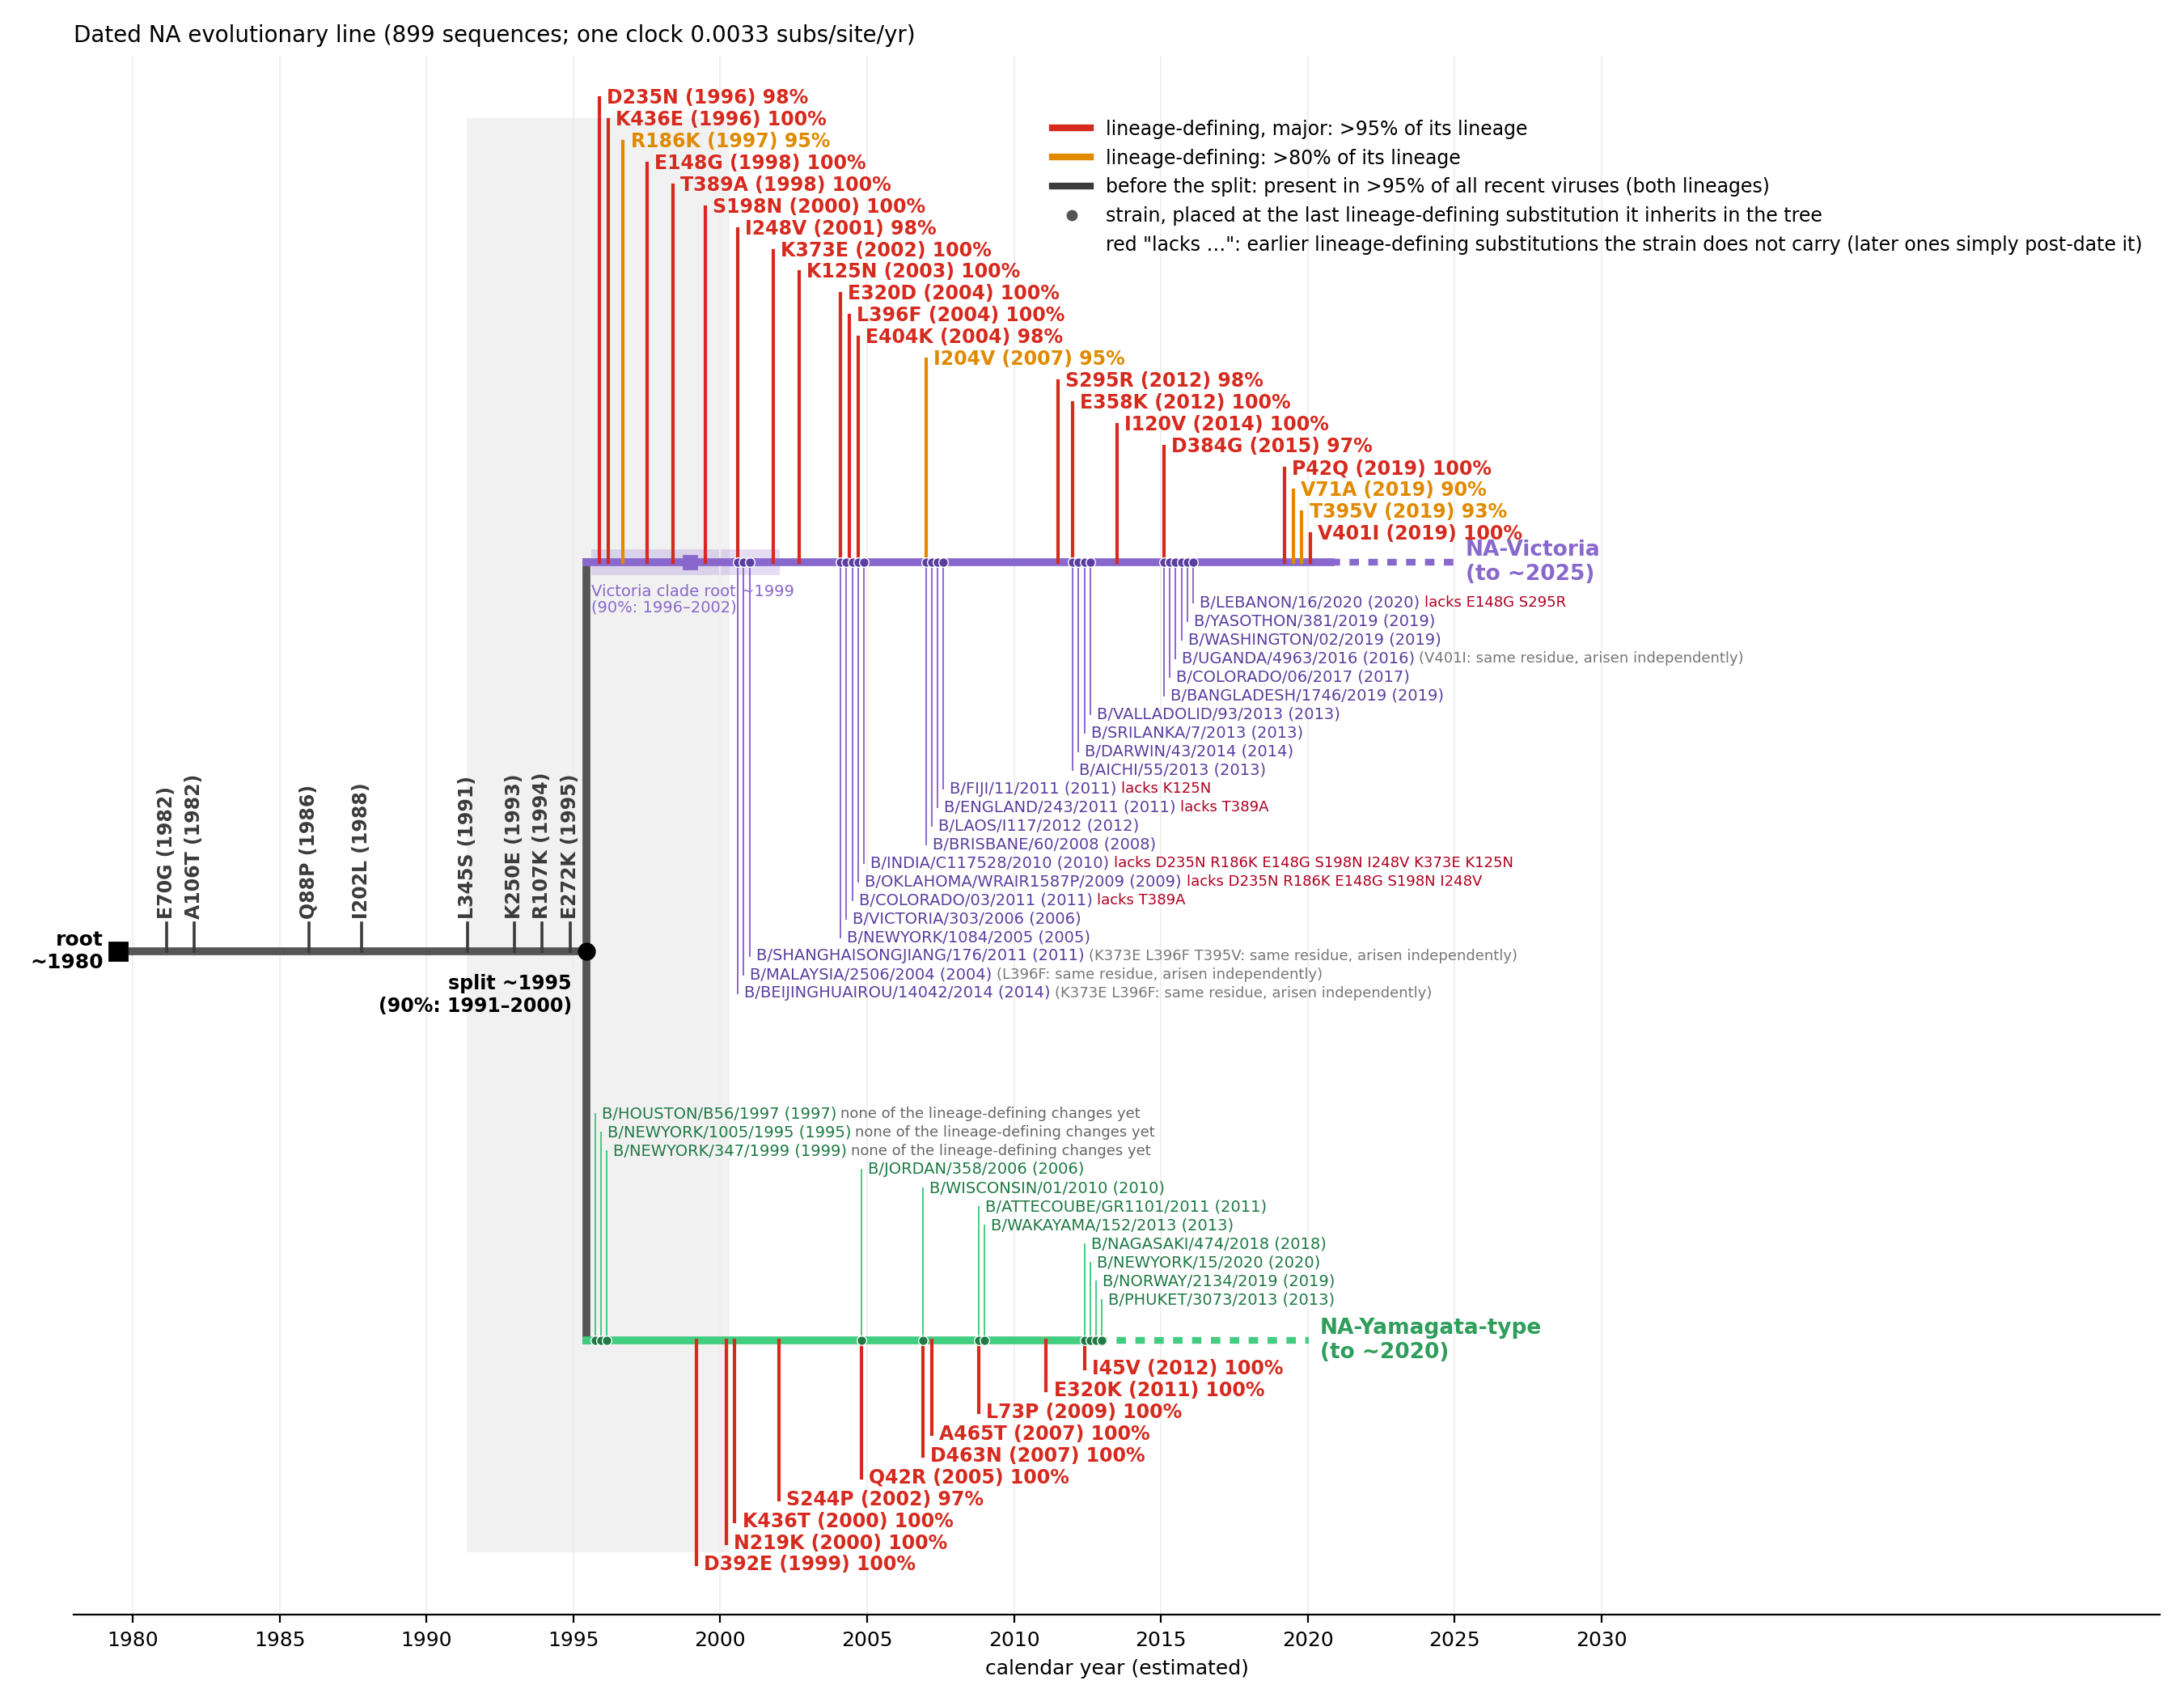

Displaying: t3_phylogram_899_A4.png


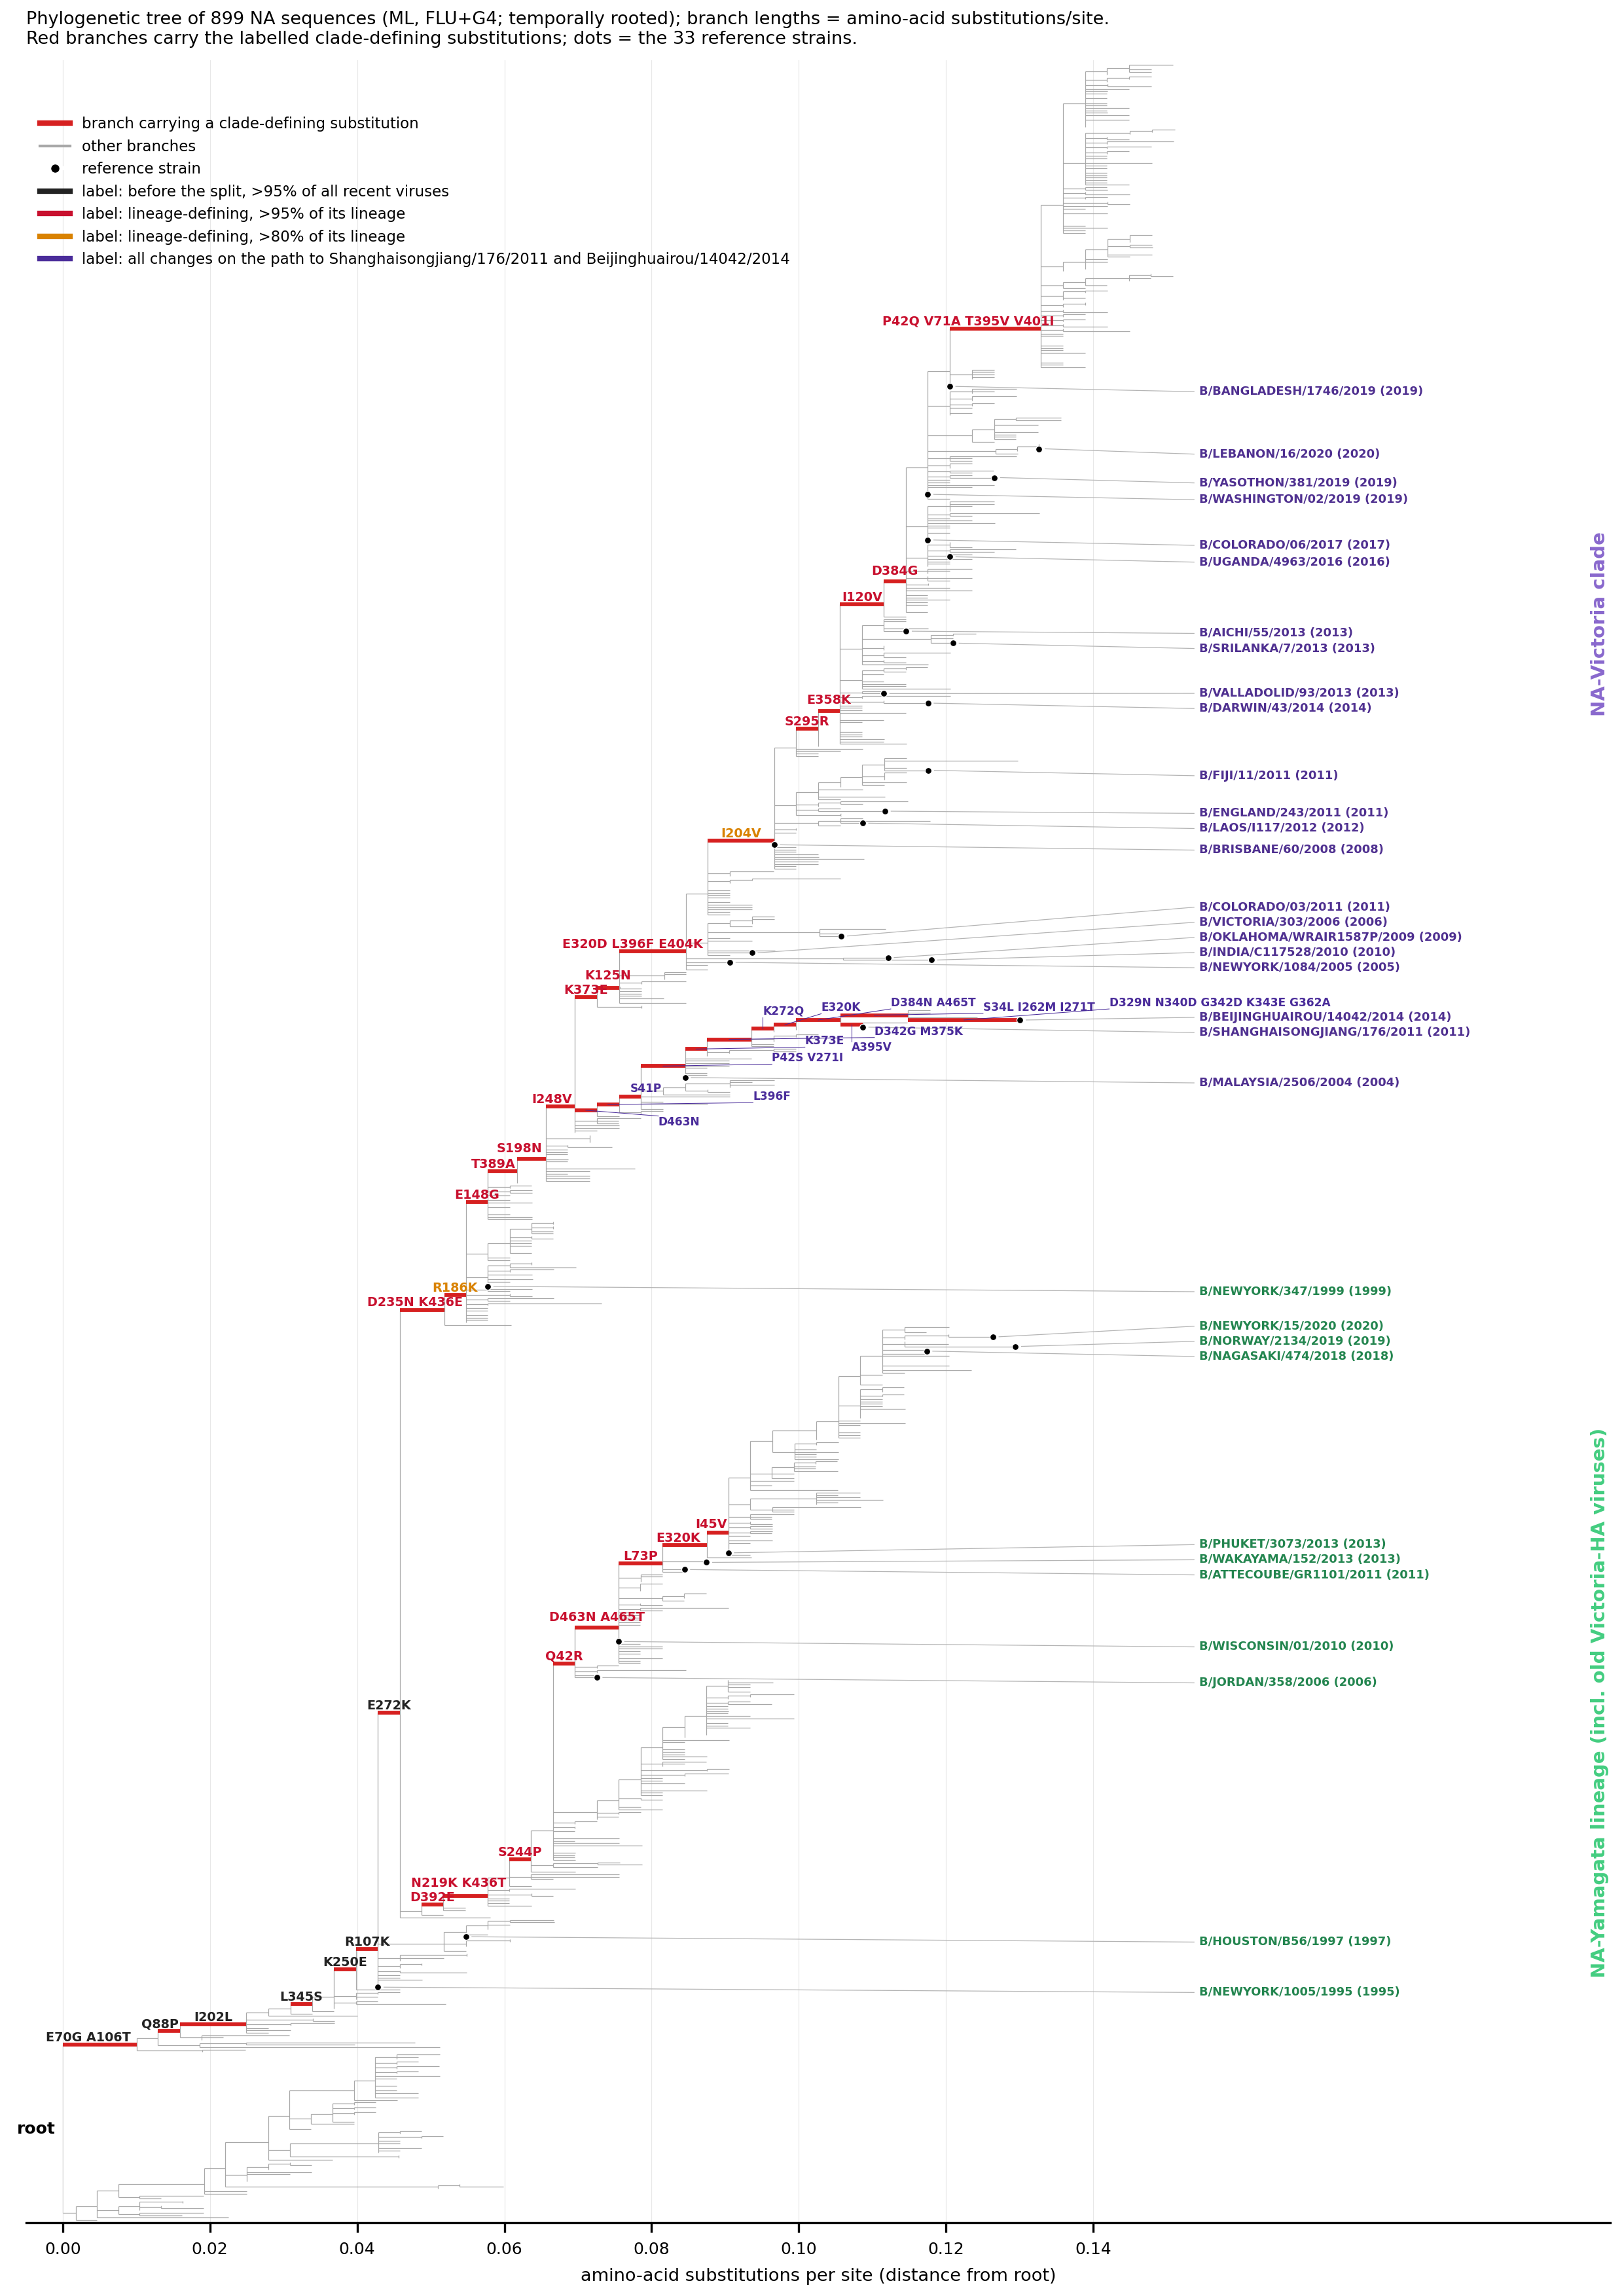

Displaying: t3_root_to_tip_regression.png


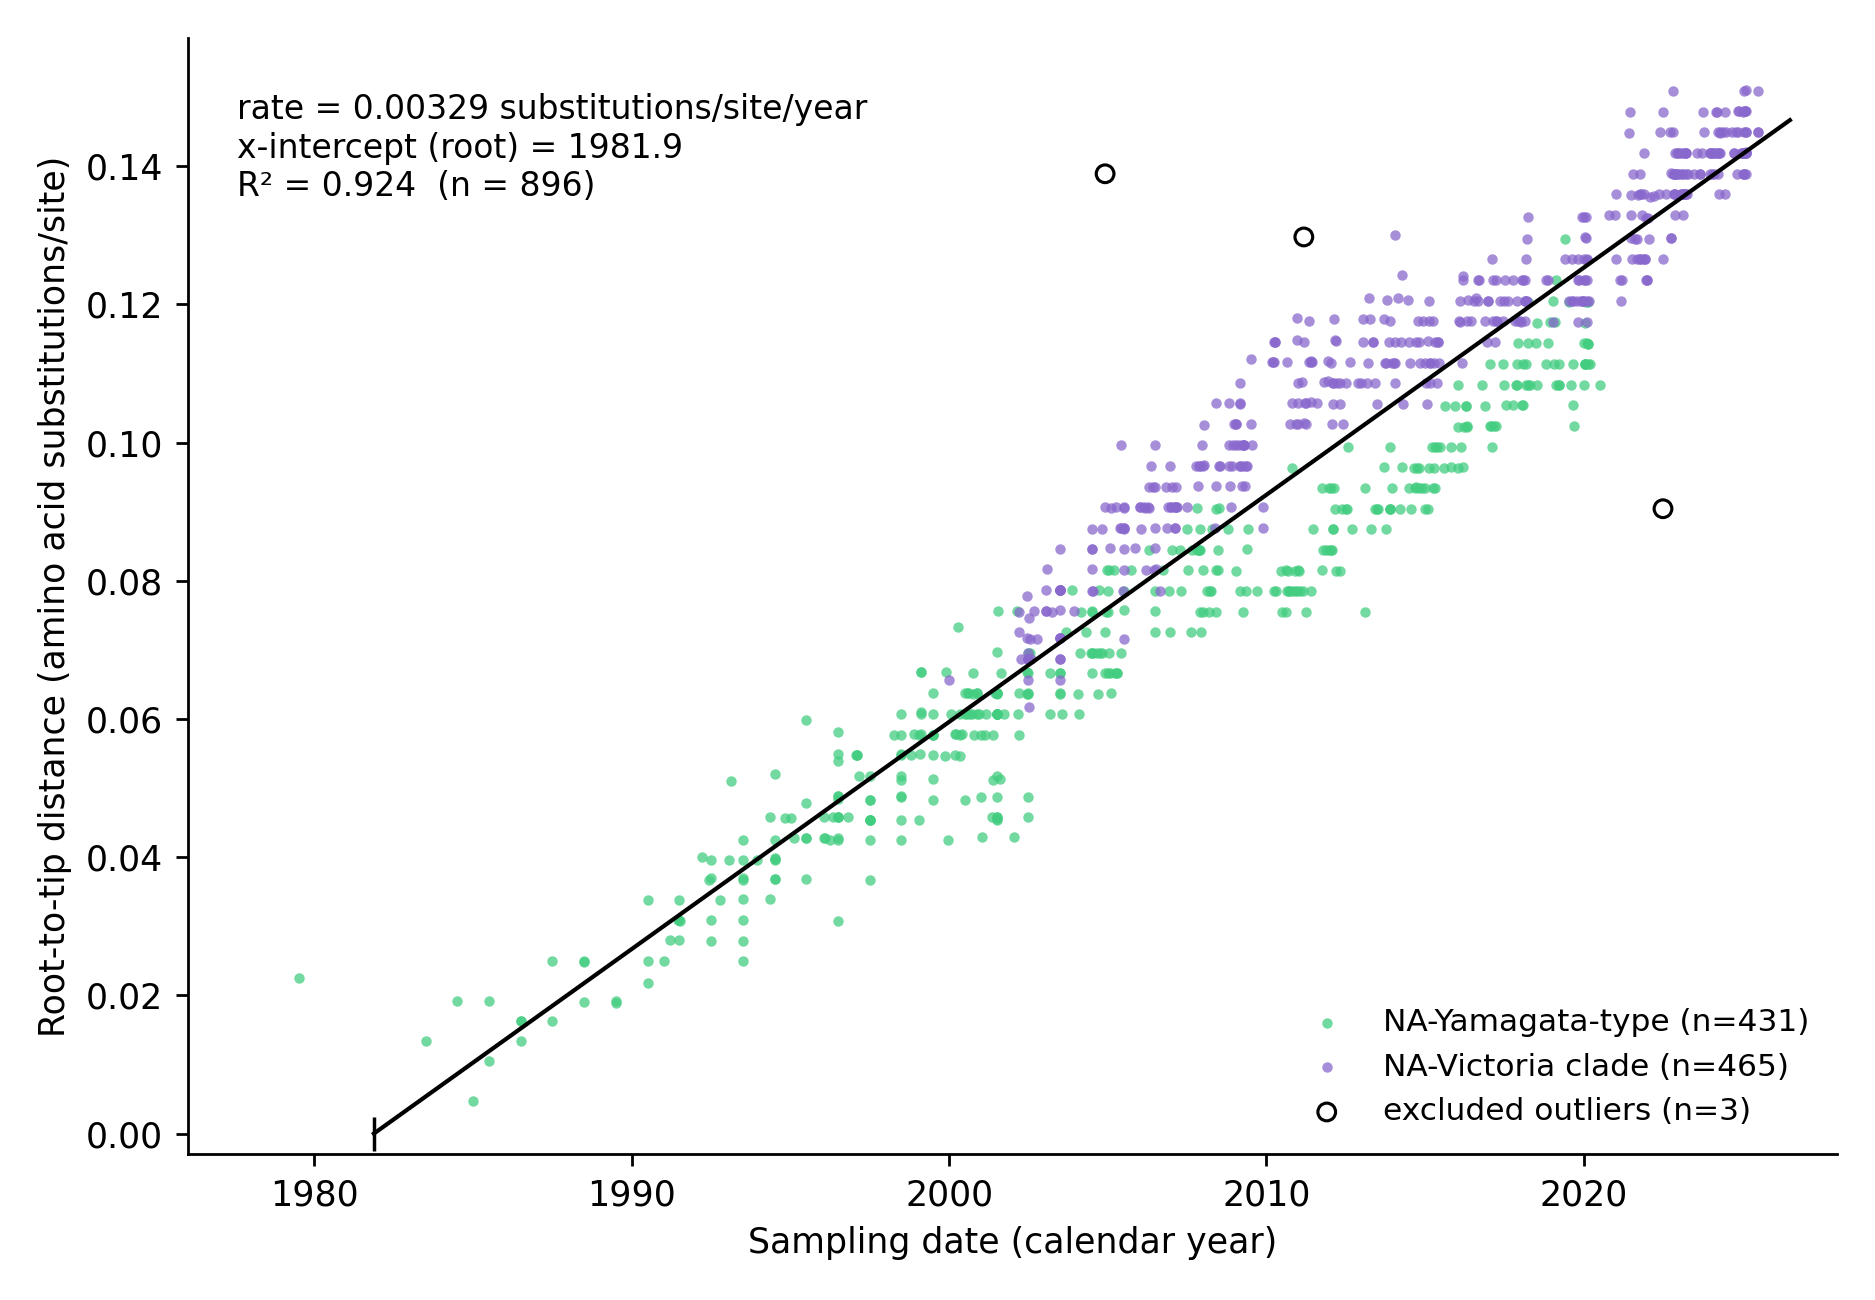

Displaying: t3_root_to_tip_by_lineage.png


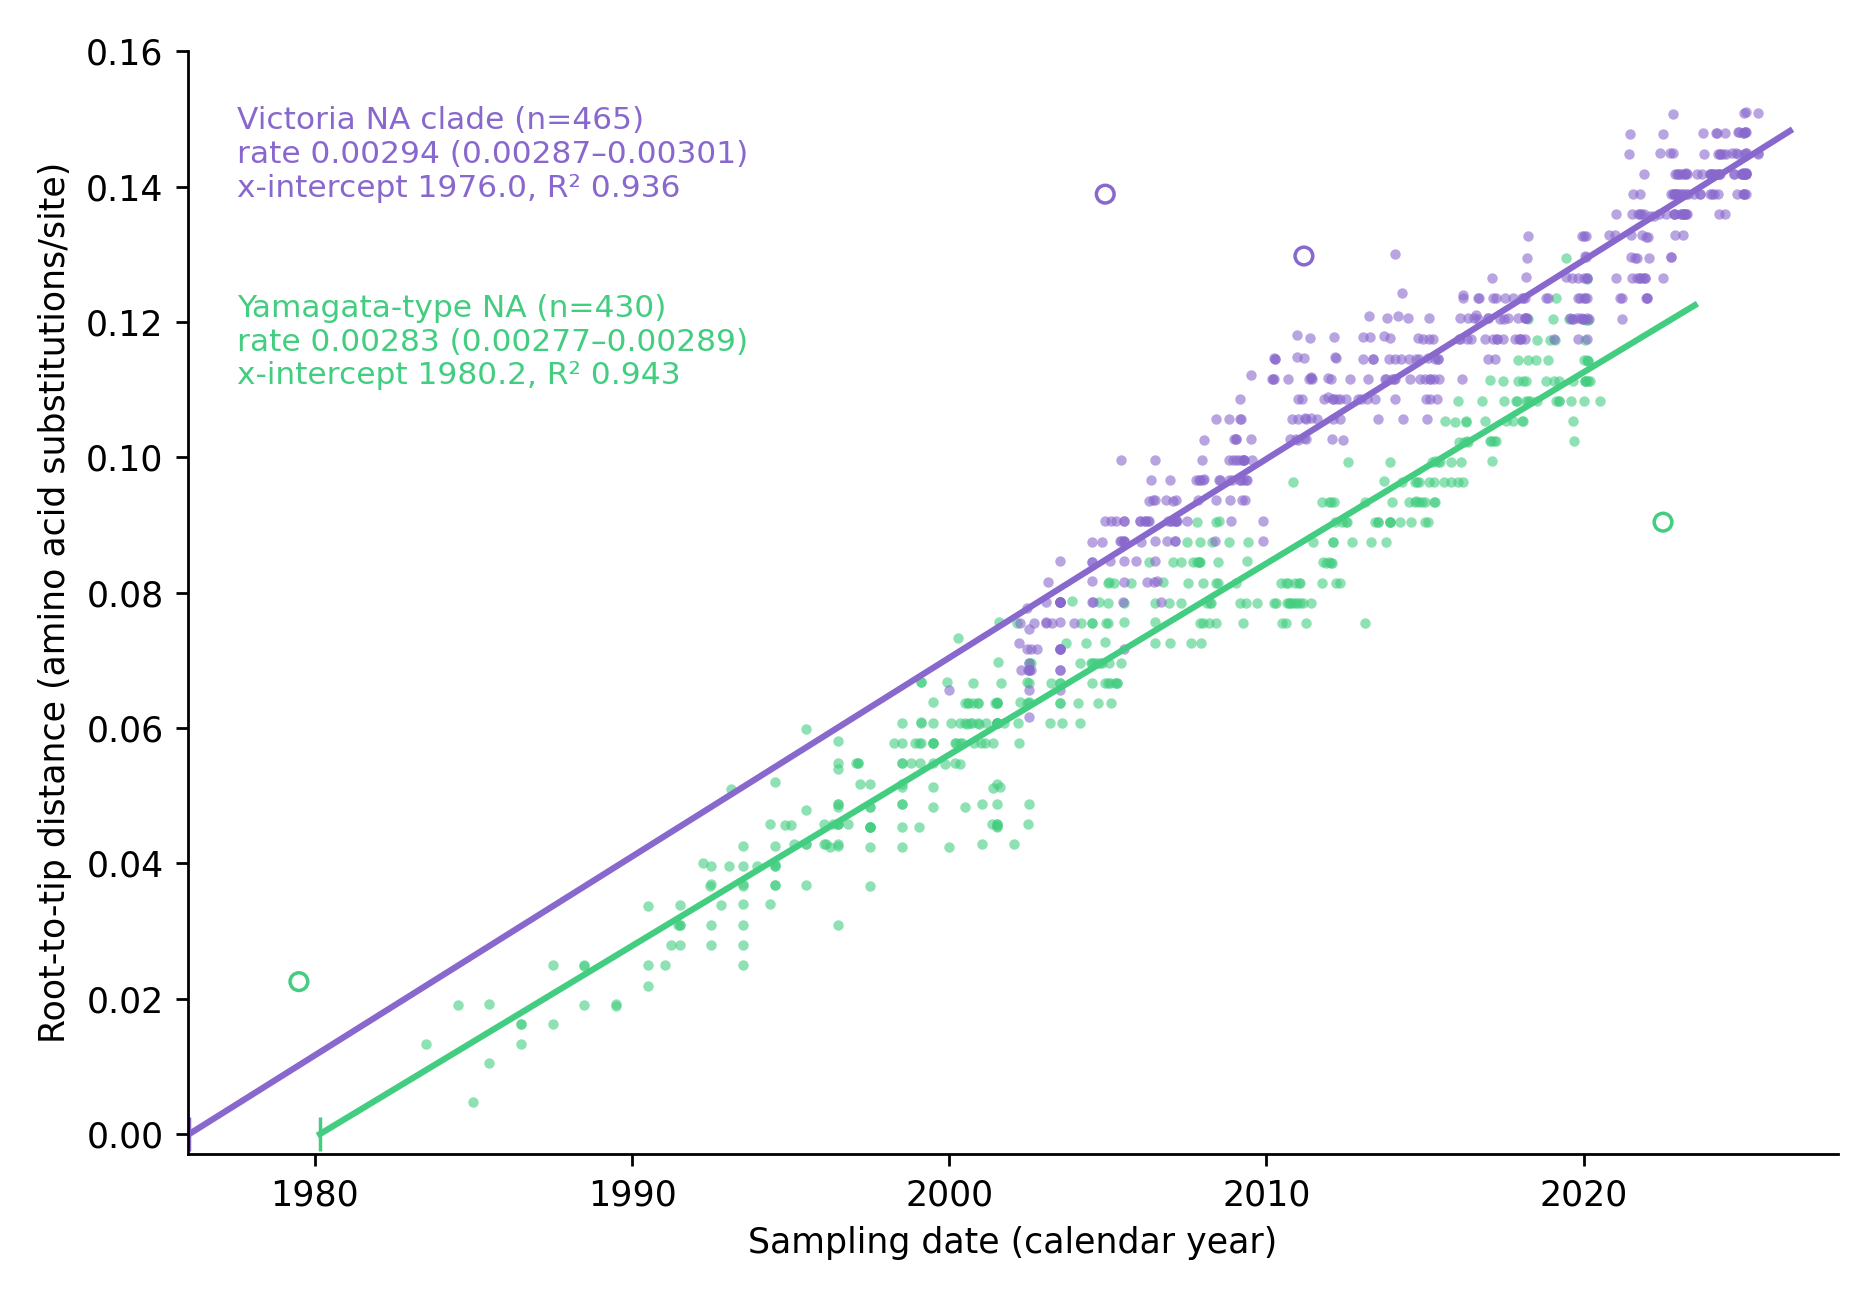

In [24]:
import os
from IPython.display import Image, display

image_files = ('t3_timeline_compact.png', 't3_phylogram_899_A4.png', 't3_root_to_tip_regression.png', 't3_root_to_tip_by_lineage.png')

for f in image_files:
    path = '/content/results/' + f
    if os.path.exists(path):
        print(f"Displaying: {f}")
        display(Image(path, width=1000))
    else:
        print(f"Warning: {f} not found. Please ensure the preceding generation scripts run successfully without errors.")

In [20]:
!ls /content/results
!cd /content/results && IBV_DIR=/content/results python3 /content/ibv_code/02_dating.py nc.treefile 2>&1 | tail -25
!cd /content/results && IBV_DIR=/content/results python3 /content/ibv_code/03_timeline_figure.py 2>&1 | tail -25

aln_c2.fa  nc.ckp.gz  nc.log	 nc.stdout    nc.uniqueseq.phy	sequences.fasta
nc.bionj   nc.iqtree  nc.mldist  nc.treefile  required3.tsv
Exception in thread Thread-1 (main):
Traceback (most recent call last):
  File "/usr/lib/python3.13/threading.py", line 1044, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.13/threading.py", line 995, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/content/ibv_code/02_dating.py", line 7, in main
    g={'__name__':'vh'}; exec(open(os.path.join(HERE,'common.py')).read(),g); globals().update(g)
                         ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<string>", line 11
    a,b=l.rstrip('
                 ^
SyntaxError: unterminated string literal (detected at line 11)
Traceback (most recent call last):
  File "/content/ibv_code/03_timeline_figure.py", line 7, in <module>
    _g=load_common(); globals().update(_g)
  File "/content/ibv_code/bo

## 7. Download everything

In [25]:
!cd /content && zip -qr results.zip results -x 'results/sequences.fasta'
from google.colab import files
files.download('/content/results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>